# Septoria severity and yield loss in winter wheat (West Lafayette, Indiana)

This notebook simulates septoria tritici blotch severity, and the yield loss it
causes, for 19 winter-wheat seasons at West Lafayette, Indiana (sown
1972–1990, harvested 1973–1991). It has two stages.

1. **Crop growth** with torchcrop's **Lintul5** model in water- and
   nitrogen-limited production mode (rainfed, with the trial's nitrogen
   fertiliser):
   1. calibrate phenology (TSUM1, TSUM2) against reference anthesis and
      maturity dates;
   2. calibrate the level of simulated yield (the fertiliser-N recovery
      fraction) against detrended USDA NASS county yields.
2. **Disease** with simpest's **FraNchEstYN** model, driven by the calibrated
   crop growth:
   1. screen the disease parameters for sensitivity (Morris);
   2. calibrate the sensitive parameters against observed septoria severity;
   3. simulate severity and the resulting yield loss, then check the fit and
      a hold-out.

Each "location" in the torchcrop dataset is one **sowing season** at the same
site, with its own sowing day (`IDPL` in `site.csv`). Each season's weather
starts on 1 January of the sowing year and runs 570 days, so the model is
driven with `start_doy=1` and relies on its internal **sowing latch** for the
pre-sowing spin-up.


## 1. Setup


In [1]:
import copy
import os
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import Dataset

from torchcrop import (CropParameters, SoilParameters, SiteParameters, Lintul5Model, WeatherDriver,)

plt.rcParams["font.family"] = "DeJavu Serif"
plt.rcParams["font.serif"] = "Times New Roman"

DATA_DIR = Path("west_lafayette_indiana_72_90")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [2]:
class TorchCropDataset(Dataset):
    """Reads per-location weather, soil, and site data for torchcrop.

    Directory layout (under ``DATA_DIR``)::

        weather/<location>.csv   daily forcing, one file per location
        soil/soil.csv            one row per location, indexed by ``location``
        site/site.csv            one row per location, indexed by ``location``

    Here each "location" is actually one **sowing season** (keyed by sowing
    year) at the same West Lafayette site, since Indiana's winter-wheat
    sowing date shifts year to year -- unlike the Brandenburg reference set,
    where each location is a distinct place sown on the same calendar date.
    Each season's weather file spans a fixed-length window starting 1
    January of the sowing year and running long enough into the following
    year to reach maturity, and each site.csv row carries that season's own
    ``IDPL``.

    ``__getitem__`` returns a single sample as a dict with:

        * ``weather`` : ``[T, 8]`` float tensor in torchcrop channel order
          (DOY, davtmp, tmin, tmax, irrad, rain, vp, wind)
        * ``soil``    : dict of scalar floats keyed by ``SoilParameters`` field
        * ``site``    : dict of scalar floats keyed by ``SiteParameters`` field

    Use `collate_torchcrop` as the DataLoader ``collate_fn`` to assemble a
    batch into ready-to-run ``WeatherDriver`` / ``SoilParameters`` /
    ``SiteParameters`` objects.
    """

    # CSV weather columns, in the exact order torchcrop expects them.
    WEATHER_COLS = [
        "Date",          # -> doy
        "TempMean",      # -> davtmp (recomputed as (TempMin+TempMax)/2 below)
        "TempMin",       # -> tmin
        "TempMax",       # -> tmax
        "Radiation",     # -> irrad
        "Precipitation", # -> rain
        "VapPressure",   # -> vp
        "Windspeed",     # -> wind
    ]

    # soil.csv column -> SoilParameters field name
    SOIL_MAP = {
        "SMDRY": "wcad",       # air-dry volumetric water content [m³ m⁻³]
        "SMW": "wcwp",         # water content at wilting point [m³ m⁻³]
        "SMFC": "wcfc",        # water content at field capacity [m³ m⁻³]
        "SMO": "wcst",         # water content at saturation [m³ m⁻³]
        "CRAIRC": "crairc",    # critical air content for aeration [m³ m⁻³]
        "SMI": "wci",          # initial root-zone moisture content [m³ m⁻³]
        "SMLOWI": "wci_lower", # initial lower-zone (sub-soil) moisture [m³ m⁻³]
        "RDMSO": "rdmso",      # max rooting depth allowed by the soil [m]
        "RUNFR": "runfr",      # fraction of rainfall lost to surface runoff [0–1]
        "CFEV": "cfev",        # soil-evaporation correction factor [-] (1–4)
        "KSUB": "ksub",        # max percolation rate to deeper layers [mm d⁻¹]
        "NMINS": "nmini",      # initial mineralisable soil organic N [g N m⁻²]
        "PMINS": "pmini",      # initial mineralisable soil organic P [g P m⁻²]
        "KMINS": "kmini",      # initial mineralisable soil organic K [g K m⁻²]
        "RTNMINS": "rtnmins",  # daily N mineralisation fraction [d⁻¹]
        "RTPMINS": "rtpmins",  # daily P mineralisation fraction [d⁻¹]
        "RTKMINS": "rtkmins",  # daily K mineralisation fraction [d⁻¹]
    }

    # site.csv column -> SiteParameters field name
    SITE_MAP = {
        "LATITUDE": "latitude",
        "ALTITUDE": "altitude",
        "IDPL": "idpl",
        "CO2": "co2",
    }

    def __init__(self, weather_dir, soil_dir, site_dir, dtype=torch.float32):
        super().__init__()
        self.weather_dir = Path(weather_dir)
        self.dtype = dtype
        self.soil_data = pd.read_csv(os.path.join(soil_dir, "soil.csv")).set_index("location")
        self.site_data = pd.read_csv(os.path.join(site_dir, "site.csv")).set_index("location")
        # Locations present in both soil and site tables.
        self.locations = self.soil_data.index.intersection(self.site_data.index)

    def __len__(self):
        return len(self.locations)

    def _load_weather(self, location):
        df = pd.read_csv(self.weather_dir / f"{location}.csv", parse_dates=["Date"], dayfirst=True)
        df = df[self.WEATHER_COLS].copy()
        # SIMPLACE drives phenology with TMPA = (TMIN+TMAX)/2 (Phenology.java:513),
        # not the measured TempMean; match it to reproduce the reference.
        df["TempMean"] = (df["TempMin"] + df["TempMax"]) / 2.0
        df["Radiation"] = df["Radiation"] / 1000.0   # kJ -> MJ m-2 d-1
        df["Date"] = df["Date"].dt.dayofyear          # date -> day-of-year
        return torch.as_tensor(df.values, dtype=self.dtype)  # [T, 8]

    def __getitem__(self, idx):
        location = self.locations[idx]

        weather = self._load_weather(location)

        srow = self.soil_data.loc[location]
        soil = {field: float(srow[col]) for col, field in self.SOIL_MAP.items()}

        trow = self.site_data.loc[location]
        site = {field: float(trow[col]) for col, field in self.SITE_MAP.items()}

        return {"weather": weather, "soil": soil, "site": site}


def collate_torchcrop(batch, dtype=torch.float32):
    """Collate samples into batched torchcrop driver/parameter objects.

    Args:
        batch: list of samples produced by `TorchCropDataset.__getitem__`.
        dtype: target dtype for the assembled tensors.

    Returns:
        Tuple ``(weather, soil_params, site_params)`` where ``weather`` is a
        `WeatherDriver` of shape ``[B, T, 8]`` and ``soil_params`` /
        ``site_params`` are batched dataclasses with ``[B]`` scalar fields.
    """
    # Weather: [B, T, 8]
    weather = torch.stack([s["weather"] for s in batch], dim=0).to(dtype)
    weather = WeatherDriver(weather)

    # Soil / site: stack each field across the batch into a [B] tensor.
    soil_fields = batch[0]["soil"].keys()
    soil_kwargs = {
        f: torch.tensor([s["soil"][f] for s in batch], dtype=dtype)
        for f in soil_fields
    }
    soil_params = SoilParameters(**soil_kwargs)

    site_fields = batch[0]["site"].keys()
    site_kwargs = {
        f: torch.tensor([s["site"][f] for s in batch], dtype=dtype)
        for f in site_fields
    }
    site_params = SiteParameters(**site_kwargs)

    return weather, soil_params, site_params

In [3]:
dataset = TorchCropDataset(
    weather_dir=DATA_DIR / "weather",
    soil_dir=DATA_DIR / "soil",
    site_dir=DATA_DIR / "site",
)

print(f"Dataset: {len(dataset)} locations")

Dataset: 19 locations


Water- and nitrogen-limited production is set with two switches. Both are
needed: with `iopt = 1` the model ignores water stress even when the soil
dries out.

| Switch             | Value | Effect                                                           |
| ------------------ | ----- | ---------------------------------------------------------------- |
| `crop_params.iopt` | `3`   | Run mode = water- and nitrogen-limited → water and N stress reduce growth; P and K stay non-limiting |
| `soil_params.irri` | `0`   | No irrigation → rainfall and the soil water balance set soil moisture |

**Soil.** The soil is the same for every season (`soil/soil.csv`). The
rooting depth the model can reach is the smaller of the soil limit (`RDMSO`,
2.0 m) and the crop limit (`rdmcr`, 1.25 m in the wheat preset), so 1.25 m
here. The soil supplies 30 kg N ha⁻¹ per season by mineralisation (`NMINS`).

**Nitrogen fertiliser.** Shaner and Buechley (1995) describe the trial's
fertilisation: in the earlier years about 22 kg N ha⁻¹ before planting plus
about 90 kg N ha⁻¹ as a spring topdressing, and in later years about
130 kg N ha⁻¹, all in autumn. The paper does not say when the practice
changed or give a topdressing date. The split is used here for every season,
with the topdressing assumed on 1 April. The model takes 70 % of applied N as
recovered by the crop (`nrf`, the preset value).


In [4]:
# Assemble every season into one batch; the model runs all of them in one forward pass.
samples = [dataset[i] for i in range(len(dataset))]
weather, soil_params, site_params = collate_torchcrop(samples)

# No irrigation (IRRI=0): rainfall and the soil water balance set soil moisture.
soil_params.irri = torch.tensor(0.0)

soil_params = soil_params.to(device=device)
site_params = site_params.to(device=device)
weather = weather.to(device=device)

# Winter-wheat preset in water- and nitrogen-limited mode (IOPT=3): water
# stress (TRANRF < 1 when the root zone dries) and nitrogen stress (NNI < 1)
# reduce growth; P and K stress are switched off.
crop_params = CropParameters(crop_name="wheat")
crop_params.iopt = torch.tensor(3.0)
crop_params = crop_params.to(device=device)

sow_years = np.array([int(y) for y in dataset.locations])
G_M2_TO_KG_HA = 10.0   # torchcrop biomass is g m-2; agronomic yields are kg ha-1

# Nitrogen fertiliser as daily applications aligned with the weather days:
# [season, day, (N, P, K)] in g m-2 d-1. Amounts from Shaner and Buechley
# (1995); the topdressing date is an assumption (see the text above).
N_AT_SOWING_KG_HA = 22.0
N_SPRING_KG_HA = 90.0
N_SPRING_DATE = "04-01"   # month-day in the harvest year
KG_HA_TO_G_M2 = 0.1

sowing_doy = dataset.site_data.loc[dataset.locations, "IDPL"].to_numpy().astype(int)
fertilizer = torch.zeros(len(sow_years), weather.data.shape[1], 3, device=device)
for b, sow_year in enumerate(sow_years):
    # Day index 0 is 1 January of the sowing year.
    spring_day = (pd.Timestamp(f"{sow_year + 1}-{N_SPRING_DATE}") - pd.Timestamp(f"{sow_year}-01-01")).days
    fertilizer[b, sowing_doy[b] - 1, 0] = N_AT_SOWING_KG_HA * KG_HA_TO_G_M2
    fertilizer[b, spring_day, 0] = N_SPRING_KG_HA * KG_HA_TO_G_M2


## 2. Calibrate phenology

Lintul5's development stage (DVS) runs from 0 at emergence to 1 at anthesis
and to 2 at maturity. After anthesis it advances with thermal time alone and
reaches 2 after `TSUM2` °C d. Before anthesis, each day's thermal time is
first multiplied by a day-length factor and a vernalisation factor
(`idsl = 2`), and anthesis is reached after `TSUM1` °C d of this *effective*
thermal time. Short days and an unmet cold requirement therefore hold the
crop back in autumn and winter, as in a real winter wheat.

The torchcrop wheat preset is temperature-only (`idsl = 0`) and has no values
for either factor. They are taken from the generic winter-wheat set of the
WOFOST crop parameter file (`wheat.yaml`,
[WOFOST_crop_parameters](https://github.com/ajwdewit/WOFOST_crop_parameters))
and kept fixed:

| Parameter (WOFOST name)                    | Value                                      | Meaning                                              |
| ------------------------------------------ | ------------------------------------------ | ---------------------------------------------------- |
| `phottb` (`DLC`, `DLO`)                    | 8 h, 14 h                                  | day-length factor rises from 0 at 8 h to 1 at 14 h   |
| `vernrt` (`VERNRTB`)                       | 0 below −4 °C, 1 at 3–10 °C, 0 above 17 °C | vernal days gained per day, by mean temperature      |
| `vbase` (`VERNBASE`)                       | 14 d                                       | vernal days before development starts                |
| `versat` (`VERNSAT`)                       | 70 d                                       | vernal days at which the cold requirement is met     |
| `vernalisation_devstage` (`VERNDVS`)       | 0.3                                        | DVS at which vernalisation switches off (the preset) |

Only `TSUM1` and `TSUM2` are fitted. Neither factor depends on them, as long
as the cold requirement is met before vernalisation switches off (checked
after the fit). The fit is therefore direct: run the model once with both
sums set out of reach, read each season's effective thermal time on its
reference anthesis date, and its thermal time between the reference anthesis
and maturity dates, and take the means. The means are the least-squares
estimates in thermal-time units.

The reference dates in `phenology/phenology.csv` come from Table 1 of Shaner
and Buechley (1995, *Plant Disease* 79:928–938), which reports planting,
spike emergence (heading) and harvest of the susceptible check cultivar Monon
at the Purdue Agronomy Farm, the same trials as the septoria observations
used below. The model's sowing days (`IDPL` in `site.csv`) are these planting
dates. The paper reports no anthesis or physiological maturity, so they are
derived with thermal time (base 0 °C, from the same weather the model uses):

- anthesis: observed heading + 70 °C d (3–6 days in these seasons);
- maturity: anthesis + 750 °C d, a typical soft red winter wheat grain fill.
  Derived maturity falls before the observed harvest in every season.

`TSUM1` is therefore fitted to observations (heading, shifted by a few
days), while `TSUM2` mostly reflects the assumed 750 °C d. The paper has no
1982 crop year; that season keeps a modelled degree-day reconstruction, so it
is the one season not anchored to observations.

In [5]:
# Winter-wheat phenology: temperature, day length and vernalisation (IDSL = 2).
# Fixed values from the generic winter-wheat set of the WOFOST crop parameter
# file (wheat.yaml, github.com/ajwdewit/WOFOST_crop_parameters).
DLC, DLO = 8.0, 14.0             # critical and optimum day length [h]
VERNBASE, VERNSAT = 14.0, 70.0   # vernal days: development starts / requirement met [d]
VERNRTB = [(-8.0, 0.0), (-4.0, 0.0), (3.0, 1.0), (10.0, 1.0), (17.0, 0.0), (20.0, 0.0)]  # vernal days per day vs mean temperature [°C]

crop_params.idsl = torch.tensor(2.0, device=device)
crop_params.phottb = torch.tensor([(0.0, 0.0), (DLC, 0.0), (DLO, 1.0), (24.0, 1.0)], device=device)
crop_params.vernrt = torch.tensor(VERNRTB, device=device)
crop_params.vbase = torch.tensor(VERNBASE, device=device)
crop_params.versat = torch.tensor(VERNSAT, device=device)

In [6]:
# Reference phenology is keyed by harvest year; a season sown in year y is harvested in y + 1.
pheno_ref = pd.read_csv(DATA_DIR / "phenology" / "phenology.csv")
pheno_ref = pheno_ref.set_index(pheno_ref["harvest_year"] - 1).reindex(sow_years)
PHENO_EVENTS = {"anthesis": "flowering_date", "maturity": "maturity_date"}

# Only seasons with reference dates enter the fit.
ref_rows = np.flatnonzero(pheno_ref["flowering_date"].notna().to_numpy())
print("seasons without reference phenology:", np.delete(sow_years, ref_rows).tolist())

# Weather starts on 1 January of each sowing year, so a date's index in the
# simulation is its day count from that 1 January.
season_start = pd.to_datetime([f"{y}-01-01" for y in sow_years])[ref_rows]
obs_idx = {ev: np.asarray((pd.to_datetime(pheno_ref[col].to_numpy()[ref_rows]) - season_start).days)
           for ev, col in PHENO_EVENTS.items()}

# The model sows on site.csv's IDPL; the reference used its own sowing dates.
idpl = dataset.site_data.loc[dataset.locations, "IDPL"].to_numpy()
sow_diff = pheno_ref["sowing_doy"].to_numpy()[ref_rows] - idpl[ref_rows]
print("reference sowing DOY minus model IDPL [d]:", dict(zip(sow_years[ref_rows].tolist(), sow_diff.astype(int).tolist())))

seasons without reference phenology: []
reference sowing DOY minus model IDPL [d]: {1972: 0, 1973: 0, 1974: 0, 1975: 0, 1976: 0, 1977: 0, 1978: 0, 1979: 0, 1980: 0, 1981: 9, 1982: 0, 1983: 0, 1984: 0, 1985: 0, 1986: 0, 1987: 0, 1988: 0, 1989: 0, 1990: 0}


In [7]:
# Probe run: TSUM1 and TSUM2 are set out of reach, so no season reaches
# anthesis, and DVS x TSUM1 is the effective thermal time since emergence
# (thermal time x day-length factor x vernalisation factor).
TSUM_PROBE = 1e4
probe_params = copy.deepcopy(crop_params)
probe_params.tsum1 = torch.tensor(TSUM_PROBE, device=device)
probe_params.tsum2 = torch.tensor(1e5, device=device)
with torch.no_grad():
    probe = Lintul5Model(probe_params, soil_params, site_params).eval().to(device)(weather, start_doy=1, fertilizer=fertilizer)

# Column d + 1 holds the value at the end of simulation day d.
tt_eff = probe.dvs.cpu().numpy() * TSUM_PROBE                            # effective thermal time
tsum = torch.stack([s.tsum for s in probe.states], dim=1).cpu().numpy()  # thermal time
tt_anthesis = tt_eff[ref_rows, obs_idx["anthesis"] + 1]
tt_grain_fill = tsum[ref_rows, obs_idx["maturity"] + 1] - tsum[ref_rows, obs_idx["anthesis"] + 1]

TSUM1 = float(tt_anthesis.mean())
TSUM2 = float(tt_grain_fill.mean())
print(f"TSUM1 = {TSUM1:.0f} °C d (preset {float(crop_params.tsum1):.0f}), "
      f"TSUM2 = {TSUM2:.0f} °C d (preset {float(crop_params.tsum2):.0f})")

crop_params.tsum1 = torch.tensor(TSUM1, device=device)
crop_params.tsum2 = torch.tensor(TSUM2, device=device)

TSUM1 = 869 °C d (preset 1050), TSUM2 = 760 °C d (preset 1000)


anthesis : RMSE 3.2 d, bias +0.6 d, max |error| 6 d
maturity : RMSE 2.6 d, bias +0.4 d, max |error| 5 d


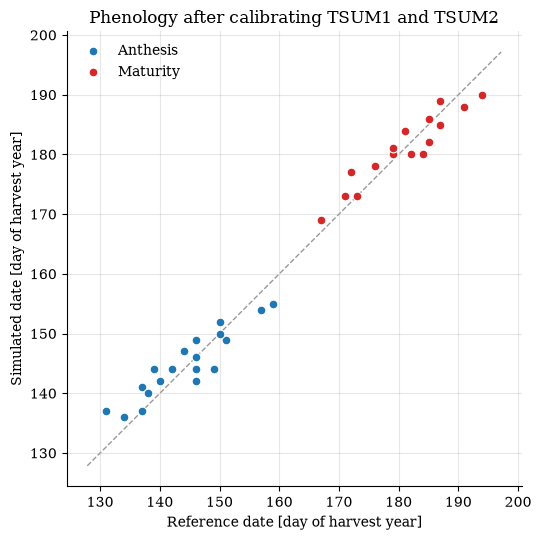

In [8]:
# Water- and nitrogen-limited run with the fitted TSUMs.
model = Lintul5Model(crop_params, soil_params, site_params).eval().to(device)
with torch.no_grad():
    output = model(weather, start_doy=1, fertilizer=fertilizer)

dvs_end = output.dvs.cpu().numpy()[:, 1:]   # DVS at the end of each simulation day
assert (dvs_end >= 2.0).any(axis=1).all(), "a season does not reach maturity"

# The TSUM1 fit assumes the cold requirement is met before vernalisation switches off.
vern_end = torch.stack([s.vern for s in output.states], dim=1).cpu().numpy()[:, 1:]
vern_off = np.argmax(dvs_end >= float(crop_params.vernalisation_devstage), axis=1)
assert (vern_end[np.arange(len(vern_off)), vern_off] >= VERNSAT).all(), "vernalisation incomplete at switch-off"

sim_idx = {"anthesis": np.argmax(dvs_end >= 1.0, axis=1)[ref_rows],
           "maturity": np.argmax(dvs_end >= 2.0, axis=1)[ref_rows]}

pheno_fit = pd.DataFrame(index=pd.Index(sow_years[ref_rows], name="sow_year"))
for ev in PHENO_EVENTS:
    pheno_fit[f"{ev}_ref"] = (season_start + pd.to_timedelta(obs_idx[ev], unit="D")).date
    pheno_fit[f"{ev}_sim"] = (season_start + pd.to_timedelta(sim_idx[ev], unit="D")).date
    pheno_fit[f"{ev}_error_d"] = sim_idx[ev] - obs_idx[ev]
    err = pheno_fit[f"{ev}_error_d"]
    print(f"{ev:9s}: RMSE {np.sqrt((err ** 2).mean()):.1f} d, bias {err.mean():+.1f} d, max |error| {err.abs().max()} d")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
for ev, color in (("anthesis", "#1f77b4"), ("maturity", "#d62728")):
    doy_ref = pd.to_datetime(pheno_fit[f"{ev}_ref"]).dt.dayofyear
    doy_sim = pd.to_datetime(pheno_fit[f"{ev}_sim"]).dt.dayofyear
    ax.scatter(doy_ref, doy_sim, s=40, color=color, edgecolor="white", linewidth=0.8, label=ev.capitalize(), zorder=3)
lo, hi = ax.get_xlim()
ax.plot([lo, hi], [lo, hi], color="0.6", lw=1, ls="--", zorder=1)
ax.set_xlabel("Reference date [day of harvest year]")
ax.set_ylabel("Simulated date [day of harvest year]")
ax.set_title("Phenology after calibrating TSUM1 and TSUM2")
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.legend(frameon=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

# pheno_fit

## 3. Calibrate yield

### Observed yield (Tippecanoe County)

County-average winter wheat yields from USDA NASS for Tippecanoe County (which
contains West Lafayette), reported in bu/acre by **harvest year**. Yields rise
over the years as varieties, fertiliser and disease control improve, which a
model run with one fixed variety cannot reproduce. A straight-line trend is
fitted to the record (harvest years 1972–1991) and used below to detrend it.

Trend +66.4 kg ha-1 yr-1, RMSE around it 550 kg ha-1


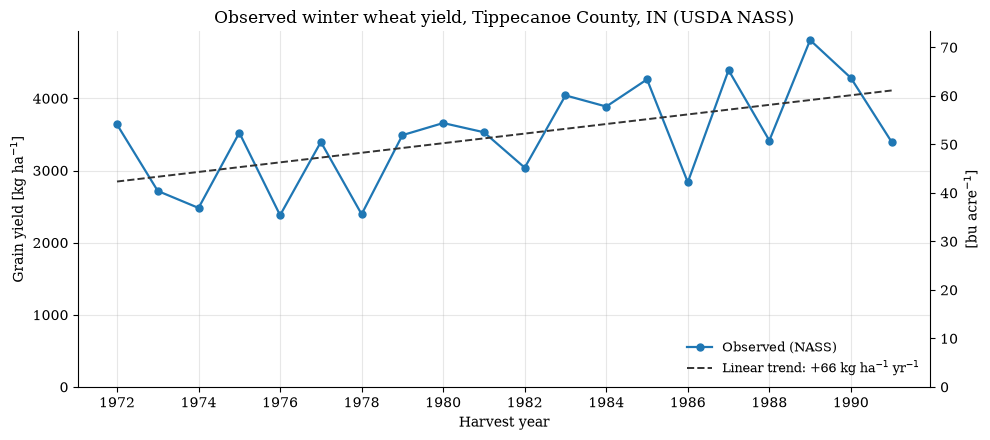

In [9]:
from simpest.models import observed_yield

# NASS "Year" is the harvest year; read_nass_yield also converts bu/acre to
# kg/ha (winter wheat is 60 lb per bushel, so 1 bu/acre ≈ 67.25 kg/ha).
obs_yield = observed_yield.read_nass_yield(DATA_DIR / "yield" / "yield.csv")
BU_ACRE_TO_KG_HA = observed_yield.BU_ACRE_TO_KG_HA

yield_trend = observed_yield.fit_linear_trend(obs_yield["harvest_year"], obs_yield["yield_kg_ha"])
print(f"Trend {yield_trend.slope:+.1f} kg ha-1 yr-1, RMSE around it {yield_trend.rmse:.0f} kg ha-1")

years = obs_yield["harvest_year"].to_numpy()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(years, obs_yield["yield_kg_ha"], color="#1f77b4", lw=1.6, marker="o", ms=5, zorder=3, label="Observed (NASS)")
ax.plot(years, yield_trend(years), color="0.2", lw=1.4, ls="--", zorder=4,
        label=f"Linear trend: {yield_trend.slope:+.0f} kg ha$^{{-1}}$ yr$^{{-1}}$")
ax.set_xlabel("Harvest year")
ax.set_ylabel("Grain yield [kg ha$^{-1}$]")
ax.set_title("Observed winter wheat yield, Tippecanoe County, IN (USDA NASS)")
ax.set_xticks(years[::2])
ax.set_ylim(0, None)
ax.grid(alpha=0.3)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
# Same quantity in the source unit, so a secondary scale is safe here.
sec = ax.secondary_yaxis("right", functions=(lambda v: v / BU_ACRE_TO_KG_HA, lambda v: v * BU_ACRE_TO_KG_HA))
sec.set_ylabel("[bu acre$^{-1}$]")
ax.legend(loc="lower right", frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

### Water- and nitrogen-limited vs observed yield

The model uses one fixed variety and management for every season, so it has
no technology trend. To compare like with like, each observed yield is
**detrended** with the trend above and expressed at the technology level of
the middle simulated harvest year (1982). With a straight-line trend this
leaves the mean observed yield of the simulated seasons unchanged: early
years move up, late years move down. The observed yields are also converted to dry
matter (NASS reports grain at 13.5 % moisture), and each season is matched to
its NASS harvest year (sowing year + 1).

The left panel compares the levels (the gap between the curves is the yield
gap). The potential yield, from the same model with water and nitrogen
stress switched off, is shown for reference: the distance between the two
simulated curves is the yield lost to water and nitrogen shortage. The right
panel compares year-to-year anomalies: if the simulated yield explained the
good and bad years, the points would follow the diagonal.


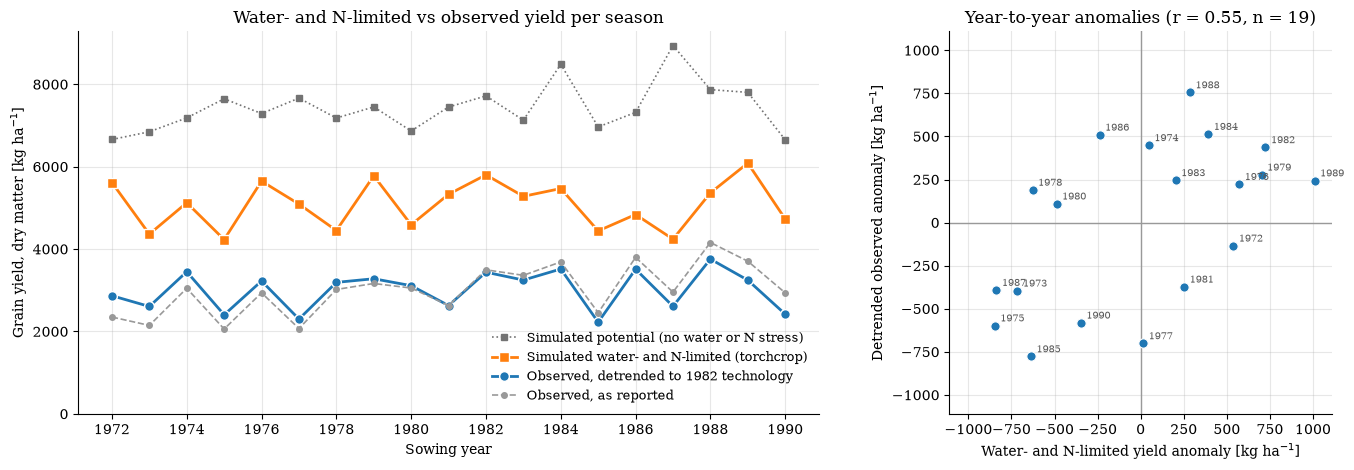

Mean observed/limited ratio (detrended): 0.59
Mean limited/potential ratio: 0.69
Anomaly correlation with detrended observed yield: limited r = 0.55, potential r = 0.19


In [10]:
# Compare the observed yields of the simulated seasons with torchcrop's
# water- and nitrogen-limited yield. Two adjustments make them comparable:
#   1. Year alignment: a season sown in year y is harvested (and reported by
#      NASS) in y + 1.
#   2. Technology: the model uses one fixed variety and management, so the
#      observed yields are detrended with the linear trend and expressed at
#      the technology level of the middle simulated harvest year, which keeps
#      their mean over the simulated seasons unchanged.
# NASS yields are at 13.5 % grain moisture; Lintul5's WSO is dry matter.
ref_harvest_year = int(round((sow_years + 1).mean()))
cmp_df = observed_yield.compare_with_potential(
    obs_yield, sow_years, output.yield_.cpu().numpy() * G_M2_TO_KG_HA, yield_trend,
    ref_harvest_year=ref_harvest_year,
).rename(columns={"potential": "limited"})   # the helper names its simulated column "potential"

# Potential-production reference: the same model with water and nitrogen
# stress switched off (IOPT=1, automatic irrigation), to show what they cost.
pot_crop, pot_soil = copy.deepcopy(crop_params), copy.deepcopy(soil_params)
pot_crop.iopt = torch.tensor(1.0, device=device)
pot_soil.irri = torch.tensor(1.0, device=device)
with torch.no_grad():
    pot_output = Lintul5Model(pot_crop, pot_soil, site_params).eval().to(device)(weather, start_doy=1, fertilizer=fertilizer)
cmp_df["potential"] = pot_output.yield_.cpu().numpy() * G_M2_TO_KG_HA

# Year-to-year anomalies (deviation from each series' own mean): does the
# water- and nitrogen-limited yield explain the good and bad years?
valid = cmp_df.dropna(subset=["observed"])
anom_sim = valid["limited"] - valid["limited"].mean()
anom_obs = valid["observed_detrended"] - valid["observed_detrended"].mean()
r_anom = np.corrcoef(anom_sim, anom_obs)[0, 1]
r_anom_pot = np.corrcoef(valid["potential"], valid["observed_detrended"])[0, 1]

fig, (ax_ts, ax_sc) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})

ax_ts.plot(cmp_df["sow_year"], cmp_df["potential"], color="0.45", lw=1.2, ls=":", marker="s", ms=4,
           label="Simulated potential (no water or N stress)")
ax_ts.plot(cmp_df["sow_year"], cmp_df["limited"], color="#ff7f0e", lw=2, marker="s", ms=7,
           markeredgecolor="white", label="Simulated water- and N-limited (torchcrop)")
ax_ts.plot(cmp_df["sow_year"], cmp_df["observed_detrended"], color="#1f77b4", lw=2, marker="o", ms=7,
           markeredgecolor="white", label=f"Observed, detrended to {ref_harvest_year} technology")
ax_ts.plot(cmp_df["sow_year"], cmp_df["observed"], color="0.6", lw=1.2, ls="--", marker="o", ms=4,
           label="Observed, as reported")
ax_ts.set_xlabel("Sowing year")
ax_ts.set_ylabel("Grain yield, dry matter [kg ha$^{-1}$]")
ax_ts.set_title("Water- and N-limited vs observed yield per season")
ax_ts.set_xticks(cmp_df["sow_year"][::2])
ax_ts.set_ylim(0, None)
ax_ts.legend(loc="lower right", frameon=False, fontsize=9)

lim = 1.1 * max(anom_sim.abs().max(), anom_obs.abs().max())
ax_sc.axhline(0, color="0.6", lw=1)
ax_sc.axvline(0, color="0.6", lw=1)
ax_sc.scatter(anom_sim, anom_obs, s=45, color="#1f77b4", edgecolor="white", linewidth=0.8, zorder=3)
for sy, xa, ya in zip(valid["sow_year"], anom_sim, anom_obs):
    ax_sc.annotate(str(sy), (xa, ya), xytext=(4, 3), textcoords="offset points", fontsize=7, color="0.35")
ax_sc.set_xlim(-lim, lim)
ax_sc.set_ylim(-lim, lim)
ax_sc.set_aspect("equal")
ax_sc.set_xlabel("Water- and N-limited yield anomaly [kg ha$^{-1}$]")
ax_sc.set_ylabel("Detrended observed anomaly [kg ha$^{-1}$]")
ax_sc.set_title(f"Year-to-year anomalies (r = {r_anom:.2f}, n = {len(valid)})")

for ax in (ax_ts, ax_sc):
    ax.grid(alpha=0.3)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

fig.tight_layout()
plt.show()

print(f"Mean observed/limited ratio (detrended): {cmp_df['yield_gap_ratio'].mean():.2f}")
print(f"Mean limited/potential ratio: {(cmp_df['limited'] / cmp_df['potential']).mean():.2f}")
print(f"Anomaly correlation with detrended observed yield: limited r = {r_anom:.2f}, potential r = {r_anom_pot:.2f}")
# cmp_df.round(1)

### Calibrate simulated yield (WSO) against detrended observed yield

torchcrop is differentiable, so its parameters can be fitted by gradient
descent. `torchcrop.calibration.CalibrationManager` keeps each parameter
inside its bounds through a sigmoid transform, and L-BFGS minimises the mean
squared error between the simulated storage-organ weight at maturity (WSO)
and the detrended observed yield of every season. Phenology stays at the
TSUMs fitted in section 2.

**Which parameter.** The crop is nitrogen-limited, so the yield level is set
by how much nitrogen the crop takes up. The fitted parameter is therefore the
fertiliser-N recovery fraction `nrf`, the share of applied N that reaches the
crop (preset 0.7). Simulated yield rises steadily with `nrf`. The RUE scale
factor is not used: under nitrogen limitation yield first rises and then
falls as RUE increases, so it cannot be fitted by gradient descent, and
lowering RUE until the level matches removes the nitrogen limitation and with
it most of the year-to-year signal.

**What the fit can and cannot do.** One parameter set is shared by all 19
seasons, so the fit moves the level of the simulated yields; the
season-to-season pattern comes from the weather. The fitted `nrf` is an
*effective* value: besides fertiliser losses it absorbs every yield-limiting
factor the model still leaves out (other nutrients, weeds, pests, and also
disease). Because NASS yields already include disease losses, the calibrated
yield that FraNchEstYN treats as attainable is not fully disease-free, and
part of the septoria loss simulated in section 8 is counted twice.


In [11]:
from torchcrop.calibration import CalibrationManager, ParameterSpec

# Parameter to fit: the fertiliser-N recovery fraction. The whole batch of
# seasons shares one value, so the fit moves the level of the simulated yield;
# the season-to-season pattern comes from the weather. Phenology (tsum1/tsum2)
# stays at the values fitted in section 2.
CALIB_SPECS = [
    ParameterSpec("crop.nrf", bounds=(0.1, 0.9)),
]
MAX_EVALS = 30   # each evaluation is one forward + backward pass over all seasons

# Target: detrended observed yield (dry matter) per season, in kg ha-1.
target_kg_ha = torch.tensor(cmp_df["observed_detrended"].to_numpy(), dtype=torch.float32, device=device)
has_obs = ~torch.isnan(target_kg_ha)

# Calibrate a copy so `model` and `output` above stay the uncalibrated water- and nitrogen-limited run.
# deepcopy carries the fitted TSUMs over.
calib_model = Lintul5Model(copy.deepcopy(crop_params), soil_params, site_params).to(device)
calib_mgr = CalibrationManager(calib_model, CALIB_SPECS)

# L-BFGS with a line search: few parameters and a smooth objective, so it
# converges in a handful of evaluations. The latents are unconstrained; the
# manager maps them into the bounds on every materialize().
optimizer = torch.optim.LBFGS(calib_mgr.parameters(), lr=1.0, max_iter=MAX_EVALS, max_eval=MAX_EVALS,
                              tolerance_change=1e-4, line_search_fn="strong_wolfe")
history = []

def closure():
    optimizer.zero_grad()
    values = calib_mgr.materialize()
    sim_kg_ha = calib_model(weather, start_doy=1, fertilizer=fertilizer).yield_ * G_M2_TO_KG_HA
    loss = torch.mean((sim_kg_ha[has_obs] - target_kg_ha[has_obs]) ** 2)
    loss.backward()
    history.append({"eval": len(history), "rmse_kg_ha": float(loss.detach().sqrt()),
                    **{k: float(v.detach()) for k, v in values.items()}})
    print(f"eval {history[-1]['eval']:2d}  RMSE {history[-1]['rmse_kg_ha']:7.1f} kg ha-1  "
          + "  ".join(f"{k}={v:.3f}" for k, v in history[-1].items() if k.startswith("crop.")))
    return loss

optimizer.step(closure)
history = pd.DataFrame(history)

# Final forward pass with the calibrated values.
with torch.no_grad():
    calib_values = {k: float(v) for k, v in calib_mgr.materialize().items()}
    calib_output = calib_model(weather, start_doy=1, fertilizer=fertilizer)
cmp_df["calibrated"] = calib_output.yield_.cpu().numpy() * G_M2_TO_KG_HA
print("Calibrated:", {k: round(v, 3) for k, v in calib_values.items()})

valid = cmp_df.dropna(subset=["observed_detrended"])
fit_table = pd.DataFrame({
    "limited": observed_yield.fit_stats(valid["limited"], valid["observed_detrended"]),
    "calibrated": observed_yield.fit_stats(valid["calibrated"], valid["observed_detrended"]),
}).T.round(2)
fit_table

eval  0  RMSE  2135.1 kg ha-1  crop.nrf=0.700


eval  1  RMSE  1111.7 kg ha-1  crop.nrf=0.520


eval  2  RMSE  1092.8 kg ha-1  crop.nrf=0.192


eval  3  RMSE   827.8 kg ha-1  crop.nrf=0.247


eval  4  RMSE   954.8 kg ha-1  crop.nrf=0.491


...

eval  7  RMSE   462.8 kg ha-1  crop.nrf=0.359


eval  8  RMSE   462.8 kg ha-1  crop.nrf=0.360


eval  9  RMSE   462.8 kg ha-1  crop.nrf=0.360


Calibrated: {'crop.nrf': 0.36}


,RMSE,bias,r
limited,2135.08,2075.81,0.55
calibrated,462.85,-12.00,0.51


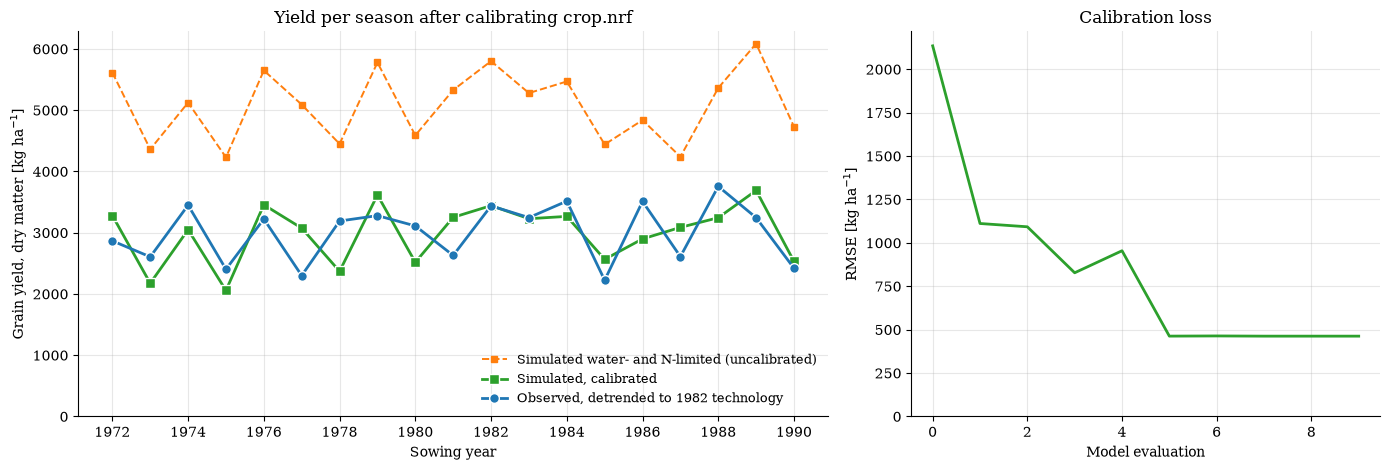

In [12]:
fig, (ax_ts, ax_loss) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})

ax_ts.plot(cmp_df["sow_year"], cmp_df["limited"], color="#ff7f0e", lw=1.4, ls="--", marker="s", ms=5,
           label="Simulated water- and N-limited (uncalibrated)")
ax_ts.plot(cmp_df["sow_year"], cmp_df["calibrated"], color="#2ca02c", lw=2, marker="s", ms=7,
           markeredgecolor="white", label="Simulated, calibrated")
ax_ts.plot(cmp_df["sow_year"], cmp_df["observed_detrended"], color="#1f77b4", lw=2, marker="o", ms=7,
           markeredgecolor="white", label=f"Observed, detrended to {ref_harvest_year} technology")
ax_ts.set_xlabel("Sowing year")
ax_ts.set_ylabel("Grain yield, dry matter [kg ha$^{-1}$]")
ax_ts.set_title("Yield per season after calibrating " + ", ".join(s.name for s in CALIB_SPECS))
ax_ts.set_xticks(cmp_df["sow_year"][::2])
ax_ts.set_ylim(0, None)
ax_ts.legend(loc="lower right", frameon=False, fontsize=9)

ax_loss.plot(history["eval"], history["rmse_kg_ha"], color="#2ca02c", lw=2)
ax_loss.set_xlabel("Model evaluation")
ax_loss.set_ylabel("RMSE [kg ha$^{-1}$]")
ax_loss.set_title("Calibration loss")
ax_loss.set_ylim(0, None)

for ax in (ax_ts, ax_loss):
    ax.grid(alpha=0.3)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

fig.tight_layout()
plt.show()

## 4. Crop growth of the calibrated run

The calibrated run (`crop_output`) drives FraNchEstYN in the rest of the
notebook. It returns two per-day trajectories that are plotted the same way:

- **State variables**: `crop_output.states`, a list of `ModelState` holding
  the model's stored pools (biomass, LAI, soil water, nutrient pools, …).
- **Diagnostic variables**: `crop_output.diagnostics`, a list of
  `DiagnosticState` holding the intermediate fluxes and stress factors
  computed each day (TRANRF, RUE, partitioning fractions, transpiration, …).

Masking to the sowing latch makes every curve **start at the day of
sowing**. The short near-vertical segment at DVS `0` is the sowing→emergence
interval; DVS then climbs `0 → 1` (anthesis) `→ 2` (maturity).


In [13]:
# The calibrated run is the crop growth used from here on.
crop_output = calib_output

from matplotlib.lines import Line2D

# Pick five random (reproducible) locations
rng = np.random.default_rng(42)
selected_idx = rng.choice(len(dataset.locations), size=5, replace=False)
locations = [dataset.locations[i] for i in selected_idx]
n_loc = len(locations)
colors = [
    "#1f77b4",  # blue
    "#d62728",  # red
    "#2ca02c",  # green
    "#ff7f0e",  # orange
    "#9467bd",  # purple
]

def mask_until_dvs2(sown_mask, dvs_vals):
    """Boolean mask selecting sown days up to and including maturity (DVS >= 2).

    Args:
        sown_mask: ``[L]`` bool array, ``True`` once the crop is sown.
        dvs_vals:  ``[L]`` development-stage values.

    Returns:
        ``[L]`` bool mask: sown days with index <= the first day DVS reaches 2.
    """
    mature = np.where(dvs_vals >= 2.0)[0]
    cutoff = mature[0] if len(mature) else len(dvs_vals)
    return sown_mask & (np.arange(len(dvs_vals)) <= cutoff)


def plot_trajectories(traj, dvs, sown, field_names, meta, *, title, ncols=4):
    """Plot every channel of ``traj`` against DVS, one line per location.

    A single helper used for both state and diagnostic figures so they share
    the same style, grid layout, labelling and legend.

    Args:
        traj:        ``[B, L, C]`` stacked trajectory array.
        dvs:         ``[B, L]`` development stage (x-axis).
        sown:        ``[B, L]`` sowing latch (> 0 once sown).
        field_names: length-``C`` list naming the channels of ``traj``.
        meta:        ``{field: (label, unit)}`` used for the panel titles.
        title:       figure super-title.
        ncols:       number of subplot columns.
    """
    nrows = int(np.ceil(len(field_names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 2.4 * nrows), sharex=True)
    axes = axes.ravel()

    for ax, fld in zip(axes, field_names):
        j = field_names.index(fld)
        for c, b in enumerate(selected_idx):
            mask = mask_until_dvs2(sown[b] > 0, dvs[b])
            ax.plot(dvs[b][mask], traj[b, mask, j], color=colors[c], lw=1.2, alpha=0.9)
        label, unit = meta.get(fld, (fld, ""))
        ax.set_title(f"{label} [{unit}]" if unit else label, fontsize=11)
        ax.grid(alpha=0.3)
        ax.margins(x=0.02)

    # Hide unused panels; label the x-axis on the bottom row of plotted panels.
    for ax in axes[len(field_names):]:
        ax.axis("off")
    for ax in axes[max(0, len(field_names) - ncols):len(field_names)]:
        ax.set_xlabel("DVS")

    handles = [Line2D([0], [0], color=colors[i], lw=2) for i in range(n_loc)]
    fig.legend(
        handles,
        [str(loc) for loc in locations],
        title="Location",
        loc="lower center",
        ncol=n_loc,
        fontsize=12,
        bbox_to_anchor=(0.5, 0.01),
        frameon=False,
    )
    fig.suptitle(title, fontsize=13)
    fig.tight_layout(rect=[0, 0.04, 1, 0.99])
    plt.show()

### State variables vs DVS

Stack the per-day `ModelState` snapshots into a `[B, T+1, C]` array and plot
every stored state variable against DVS with the shared helper.


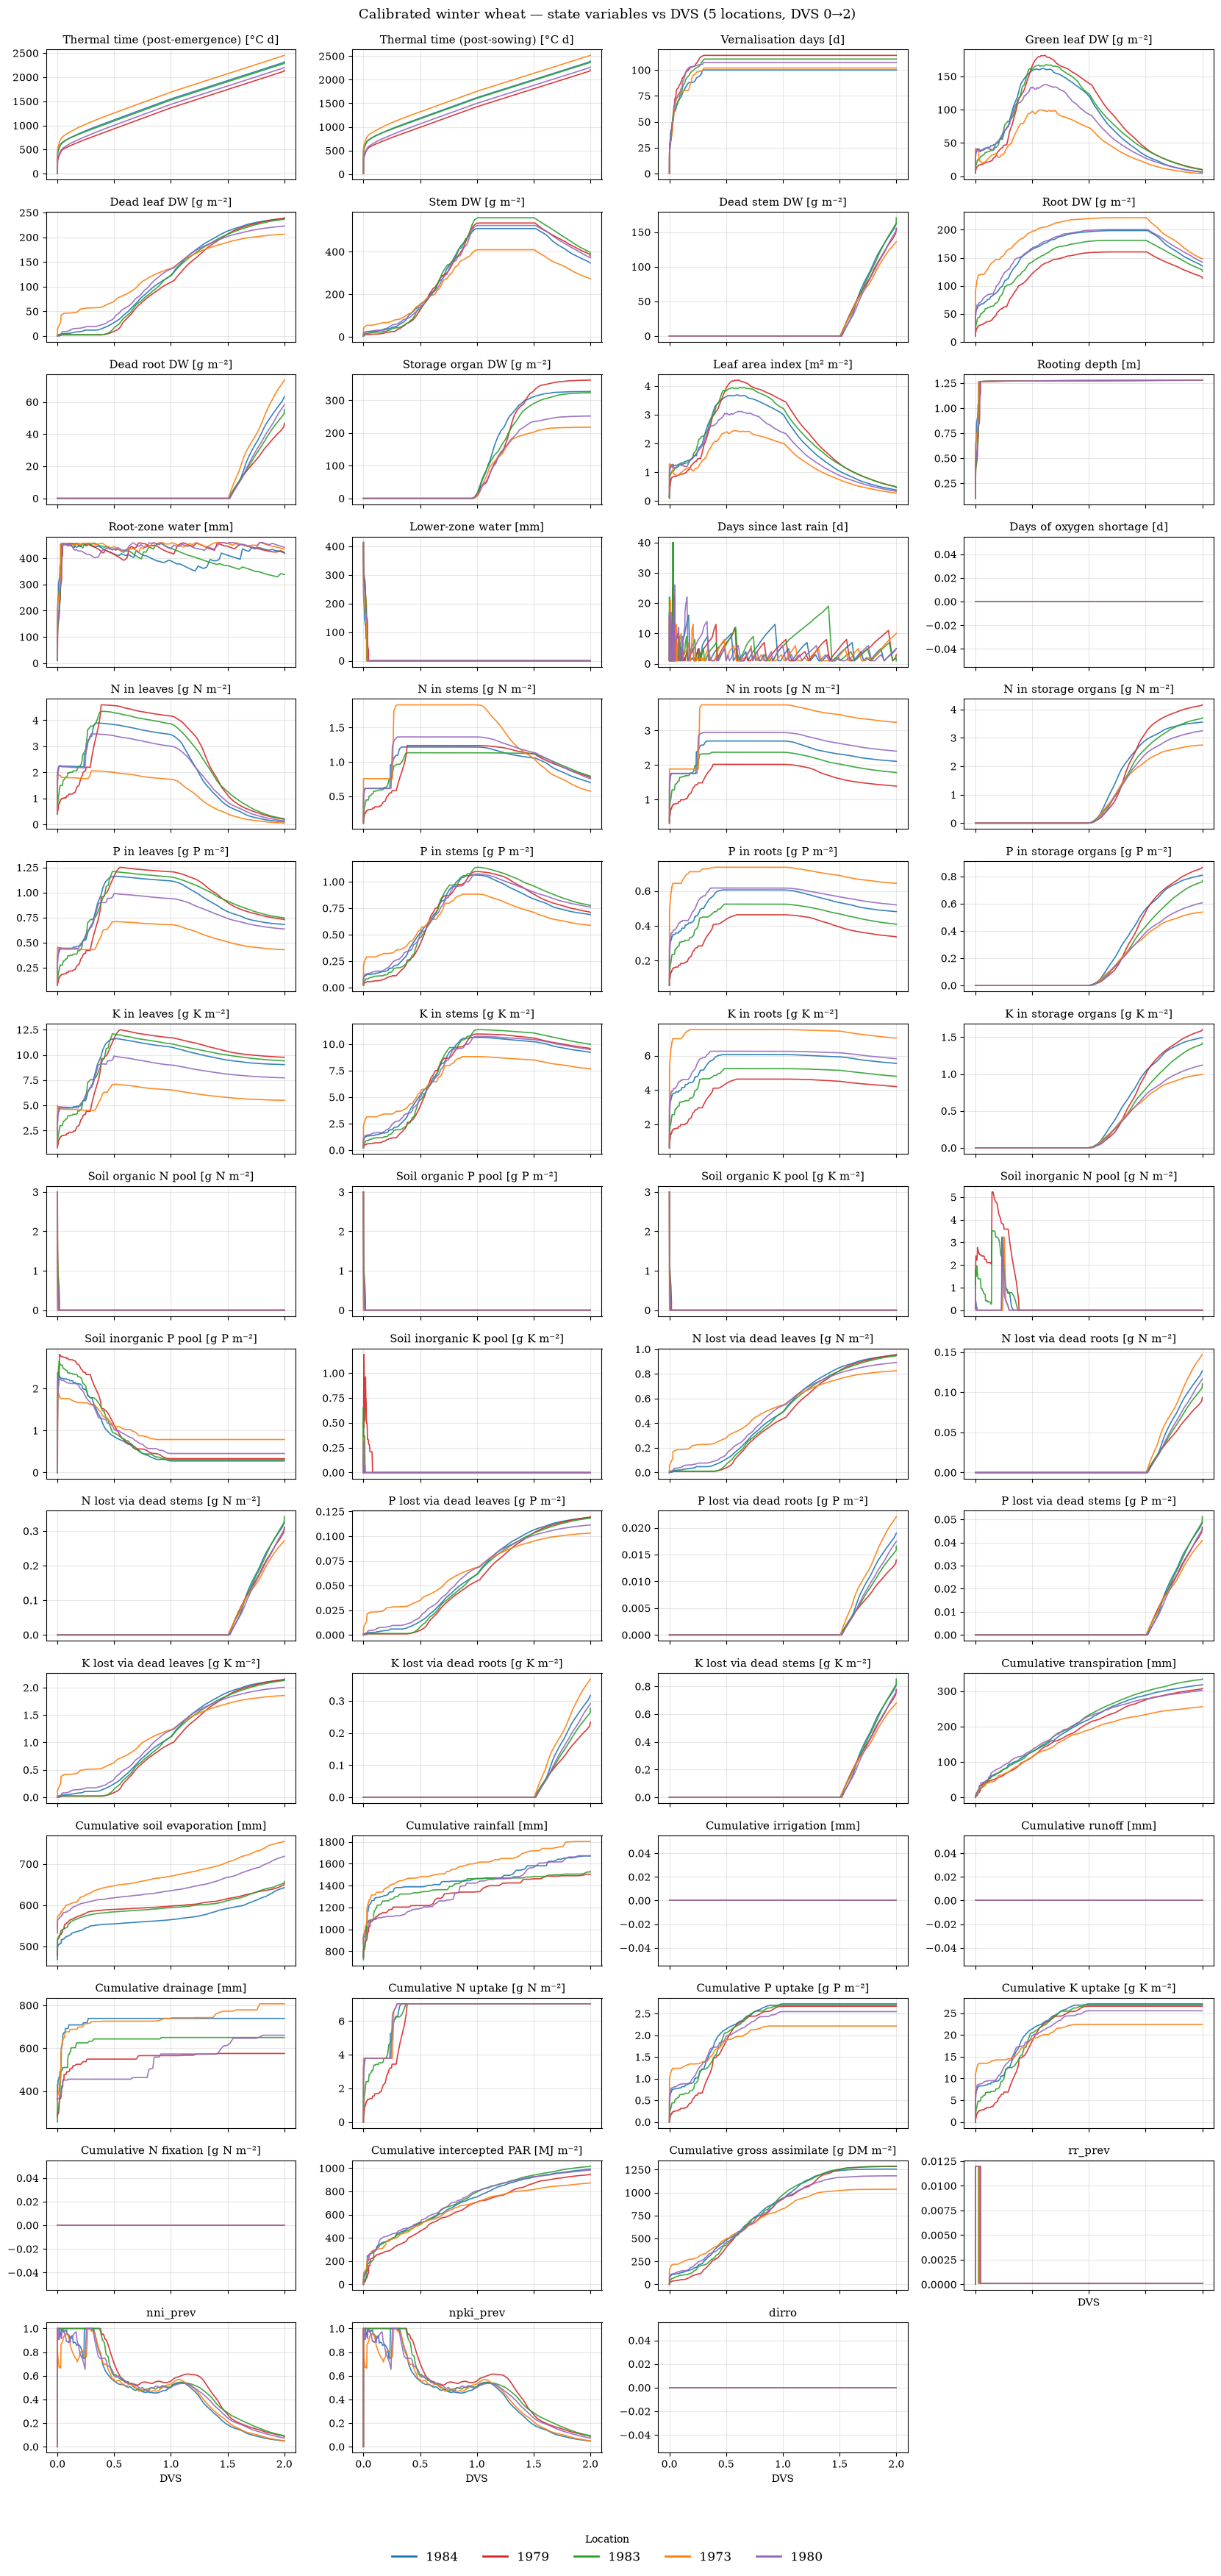

In [14]:
# Label + unit for each ModelState field.
STATE_META = {
    "tsum": ("Thermal time (post-emergence)", "°C d"),
    "tsump": ("Thermal time (post-sowing)", "°C d"),
    "vern": ("Vernalisation days", "d"),
    "wlv": ("Green leaf DW", "g m⁻²"),
    "wlvd": ("Dead leaf DW", "g m⁻²"),
    "wst": ("Stem DW", "g m⁻²"),
    "wstd": ("Dead stem DW", "g m⁻²"),
    "wrt": ("Root DW", "g m⁻²"),
    "wrtd": ("Dead root DW", "g m⁻²"),
    "wso": ("Storage organ DW", "g m⁻²"),
    "lai": ("Leaf area index", "m² m⁻²"),
    "rootd": ("Rooting depth", "m"),
    "wa": ("Root-zone water", "mm"),
    "wa_lower": ("Lower-zone water", "mm"),
    "dslr": ("Days since last rain", "d"),
    "dsos": ("Days of oxygen shortage", "d"),
    "anlv": ("N in leaves", "g N m⁻²"),
    "anst": ("N in stems", "g N m⁻²"),
    "anrt": ("N in roots", "g N m⁻²"),
    "anso": ("N in storage organs", "g N m⁻²"),
    "aplv": ("P in leaves", "g P m⁻²"),
    "apst": ("P in stems", "g P m⁻²"),
    "aprt": ("P in roots", "g P m⁻²"),
    "apso": ("P in storage organs", "g P m⁻²"),
    "aklv": ("K in leaves", "g K m⁻²"),
    "akst": ("K in stems", "g K m⁻²"),
    "akrt": ("K in roots", "g K m⁻²"),
    "akso": ("K in storage organs", "g K m⁻²"),
    "nmin": ("Soil organic N pool", "g N m⁻²"),
    "pmin": ("Soil organic P pool", "g P m⁻²"),
    "kmin": ("Soil organic K pool", "g K m⁻²"),
    "nmint": ("Soil inorganic N pool", "g N m⁻²"),
    "pmint": ("Soil inorganic P pool", "g P m⁻²"),
    "kmint": ("Soil inorganic K pool", "g K m⁻²"),
    "nlossl": ("N lost via dead leaves", "g N m⁻²"),
    "nlossr": ("N lost via dead roots", "g N m⁻²"),
    "nlosss": ("N lost via dead stems", "g N m⁻²"),
    "plossl": ("P lost via dead leaves", "g P m⁻²"),
    "plossr": ("P lost via dead roots", "g P m⁻²"),
    "plosss": ("P lost via dead stems", "g P m⁻²"),
    "klossl": ("K lost via dead leaves", "g K m⁻²"),
    "klossr": ("K lost via dead roots", "g K m⁻²"),
    "klosss": ("K lost via dead stems", "g K m⁻²"),
    "tran_cum": ("Cumulative transpiration", "mm"),
    "evap_cum": ("Cumulative soil evaporation", "mm"),
    "rain_cum": ("Cumulative rainfall", "mm"),
    "irrig_cum": ("Cumulative irrigation", "mm"),
    "runoff_cum": ("Cumulative runoff", "mm"),
    "drain_cum": ("Cumulative drainage", "mm"),
    "nuptr_cum": ("Cumulative N uptake", "g N m⁻²"),
    "puptr_cum": ("Cumulative P uptake", "g P m⁻²"),
    "kuptr_cum": ("Cumulative K uptake", "g K m⁻²"),
    "nfixtr_cum": ("Cumulative N fixation", "g N m⁻²"),
    "parint_cum": ("Cumulative intercepted PAR", "MJ m⁻²"),
    "gtotal_cum": ("Cumulative gross assimilate", "g DM m⁻²"),
}

# Stack the per-day ModelState snapshots into a [B, T+1, C] array.
field_names = crop_output.states[0].field_names
state_traj = torch.stack([s.stack() for s in crop_output.states], dim=1).cpu().numpy()  # [B, T+1, C]
dvs_traj = crop_output.dvs.cpu().numpy()  # [B, T+1]
sown_traj = torch.stack([s.sown for s in crop_output.states], dim=1).cpu().numpy()  # [B, T+1]

# DVS itself and the binary sowing latch are not informative state curves.
plot_fields = [f for f in field_names if f not in ("dvs", "sown")]
plot_idx = [field_names.index(f) for f in plot_fields]

plot_trajectories(
    state_traj[:, :, plot_idx],
    dvs_traj,
    sown_traj,
    plot_fields,
    STATE_META,
    title="Calibrated winter wheat — state variables vs DVS (5 locations, DVS 0→2)\n",
)

### Diagnostic variables vs DVS

The diagnostics are the intermediate fluxes and stress factors computed each
day — stress factors (`TRANRF`, NNI, …), photosynthesis drivers (`RUE`,
`GTOTAL`), light interception, phenology drivers, water/nutrient fluxes and
partitioning fractions.


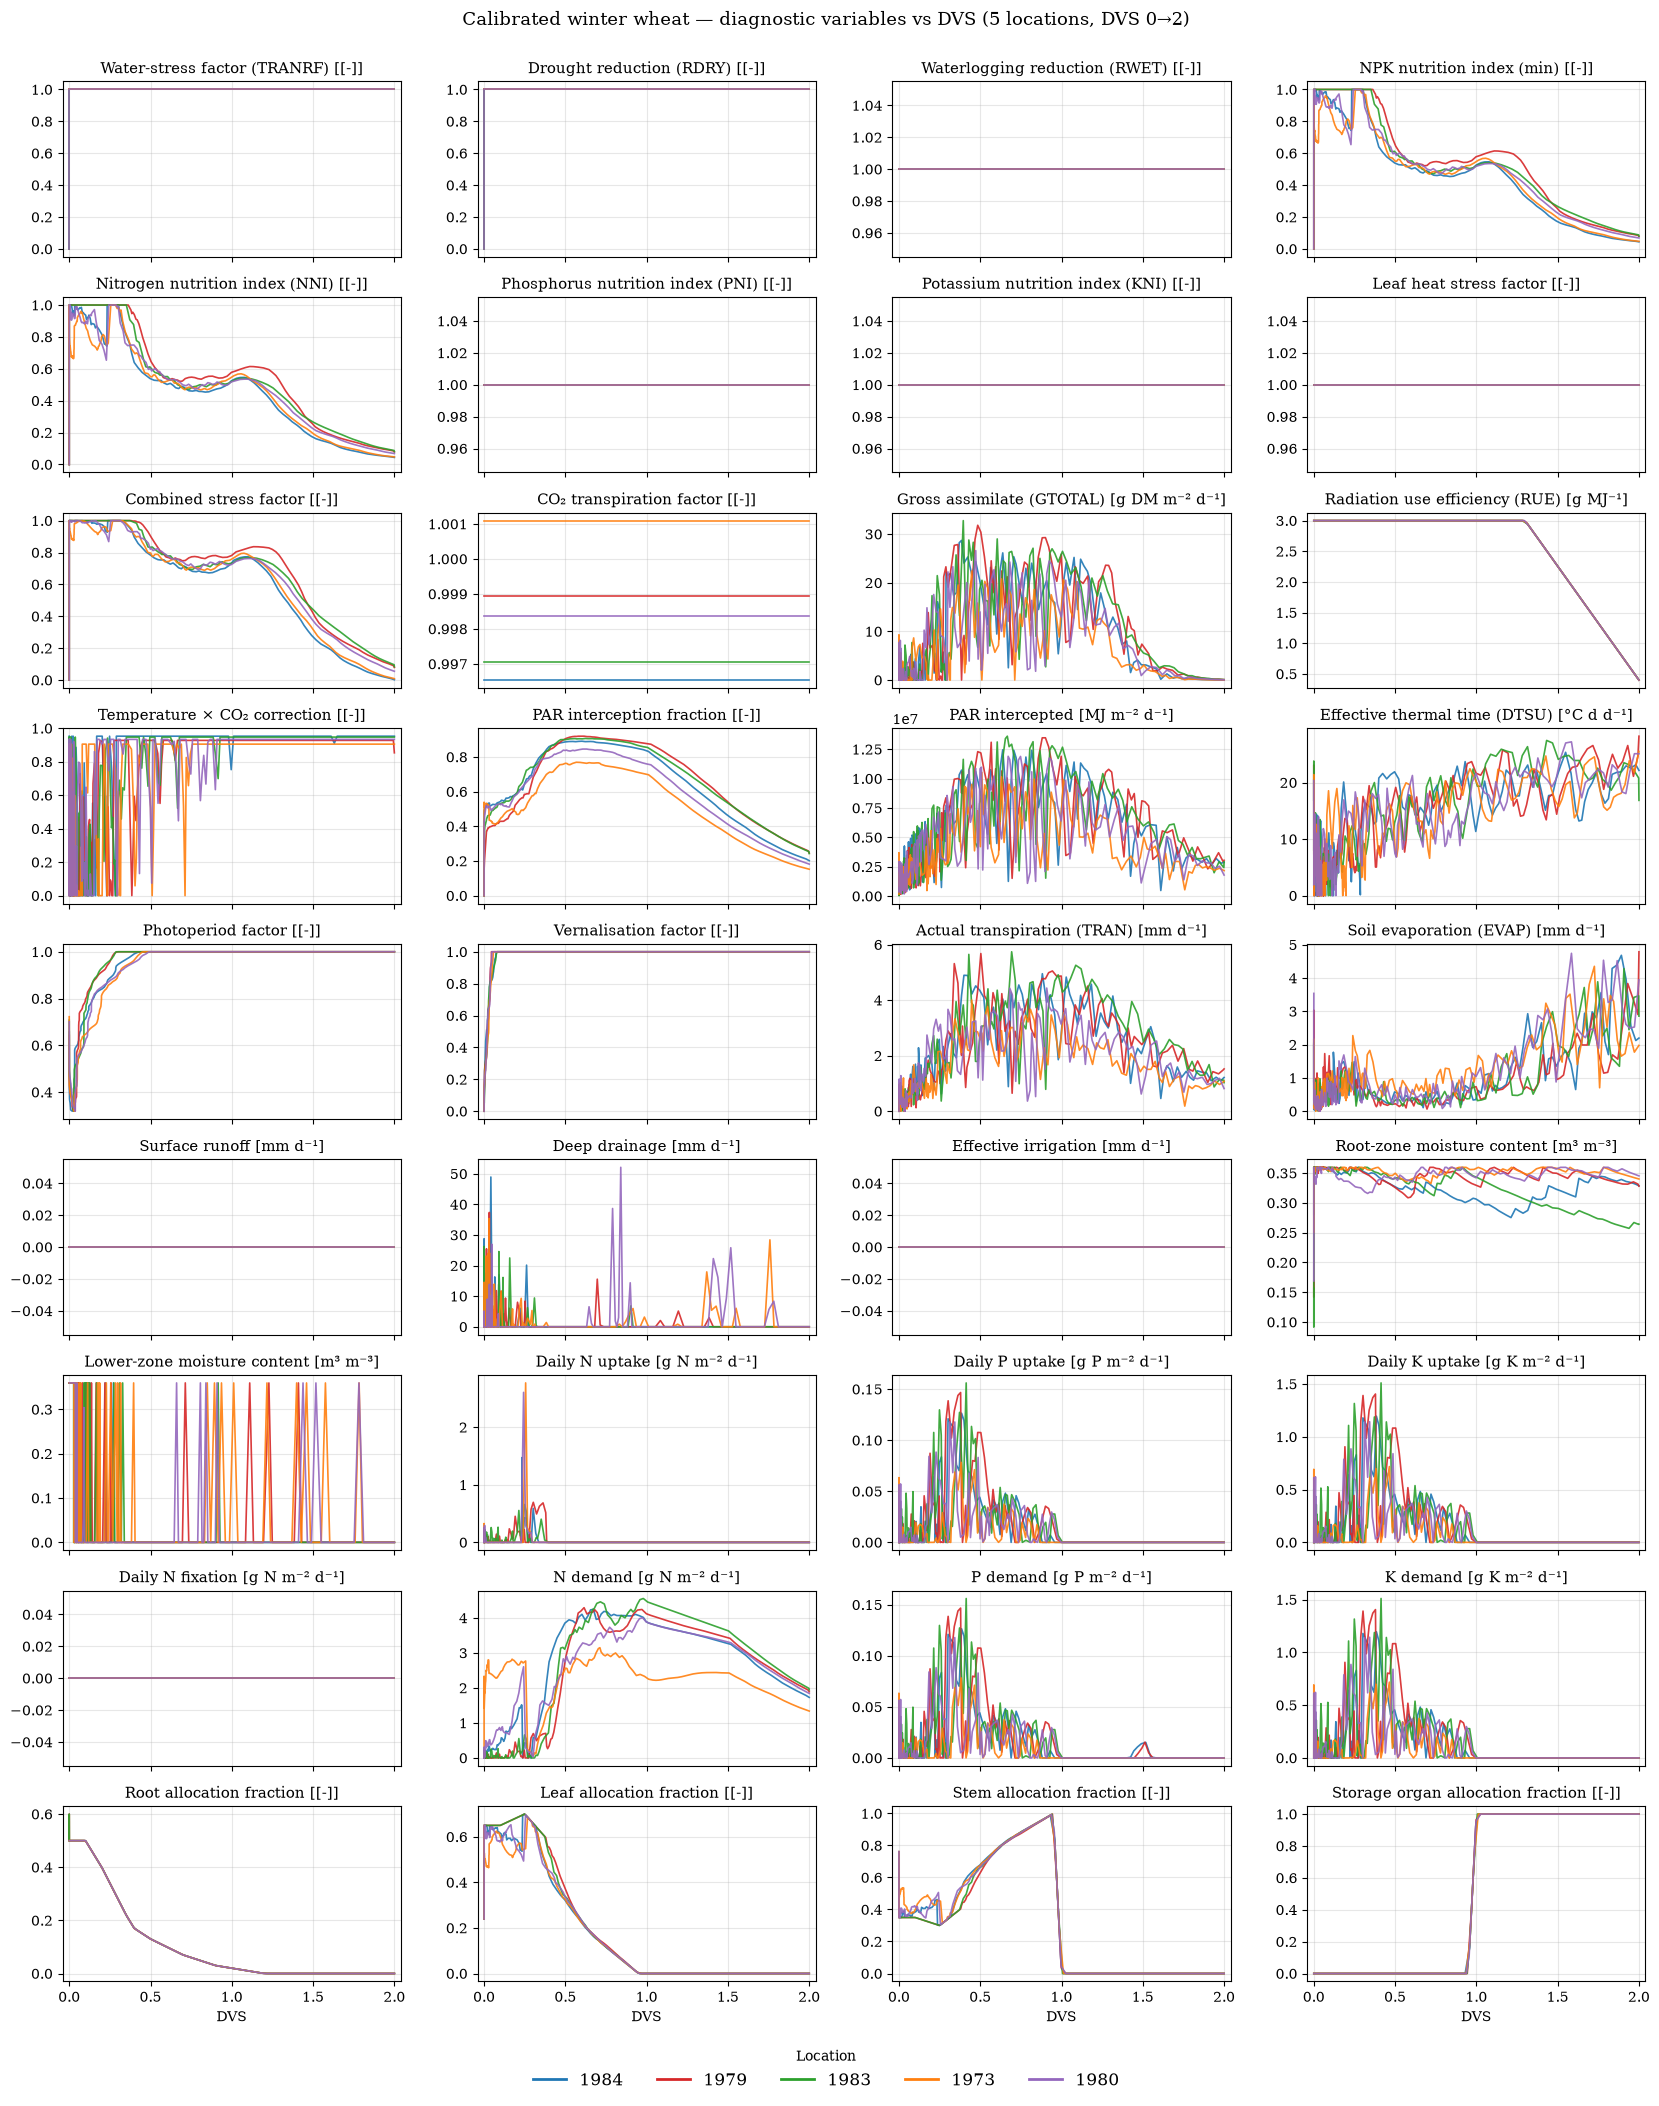

In [15]:
# Label + unit for each DiagnosticState field.
DIAG_META = {
    # Stress factors
    "tranrf": ("Water-stress factor (TRANRF)", "[-]"),
    "rdry": ("Drought reduction (RDRY)", "[-]"),
    "rwet": ("Waterlogging reduction (RWET)", "[-]"),
    "nstress": ("NPK nutrition index (min)", "[-]"),
    "nni": ("Nitrogen nutrition index (NNI)", "[-]"),
    "pni": ("Phosphorus nutrition index (PNI)", "[-]"),
    "kni": ("Potassium nutrition index (KNI)", "[-]"),
    "leaf_heat_factor": ("Leaf heat stress factor", "[-]"),
    "combined_stress": ("Combined stress factor", "[-]"),
    "co2_factor": ("CO₂ transpiration factor", "[-]"),
    # Photosynthesis / growth drivers
    "gtotal": ("Gross assimilate (GTOTAL)", "g DM m⁻² d⁻¹"),
    "rue": ("Radiation use efficiency (RUE)", "g MJ⁻¹"),
    "rtmco": ("Temperature × CO₂ correction", "[-]"),
    # Light / canopy
    "frac_intercepted": ("PAR interception fraction", "[-]"),
    "parint": ("PAR intercepted", "MJ m⁻² d⁻¹"),
    # Phenology drivers
    "dtsu": ("Effective thermal time (DTSU)", "°C d d⁻¹"),
    "photofac": ("Photoperiod factor", "[-]"),
    "vernfac": ("Vernalisation factor", "[-]"),
    # Water fluxes
    "tran": ("Actual transpiration (TRAN)", "mm d⁻¹"),
    "evap": ("Soil evaporation (EVAP)", "mm d⁻¹"),
    "runoff": ("Surface runoff", "mm d⁻¹"),
    "drain": ("Deep drainage", "mm d⁻¹"),
    "rirr": ("Effective irrigation", "mm d⁻¹"),
    "smact": ("Root-zone moisture content", "m³ m⁻³"),
    "smactl": ("Lower-zone moisture content", "m³ m⁻³"),
    # Nutrient fluxes
    "nuptr": ("Daily N uptake", "g N m⁻² d⁻¹"),
    "puptr": ("Daily P uptake", "g P m⁻² d⁻¹"),
    "kuptr": ("Daily K uptake", "g K m⁻² d⁻¹"),
    "nfixtr": ("Daily N fixation", "g N m⁻² d⁻¹"),
    "n_demand": ("N demand", "g N m⁻² d⁻¹"),
    "p_demand": ("P demand", "g P m⁻² d⁻¹"),
    "k_demand": ("K demand", "g K m⁻² d⁻¹"),
    # Partitioning fractions
    "fr": ("Root allocation fraction", "[-]"),
    "fl": ("Leaf allocation fraction", "[-]"),
    "fs": ("Stem allocation fraction", "[-]"),
    "fo": ("Storage organ allocation fraction", "[-]"),
}

# Stack the per-day DiagnosticState snapshots into a [B, T, C] array.
diag_field_names = crop_output.diagnostics[0].field_names
diag_traj = torch.stack([s.stack() for s in crop_output.diagnostics], dim=1).cpu().numpy()  # [B, T, C]

plot_trajectories(
    diag_traj,
    dvs_traj[:, :-1],
    sown_traj[:, :-1],
    diag_field_names,
    DIAG_META,
    title="Calibrated winter wheat — diagnostic variables vs DVS (5 locations, DVS 0→2)\n",
)

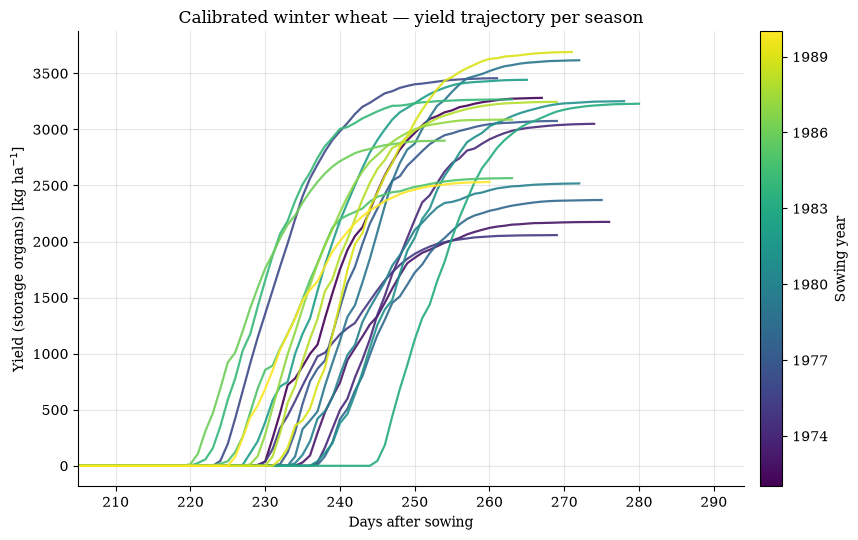

In [16]:
# Calibrated yield trajectory of every season, one line per sowing year.
# Sowing year is an ordered variable, so the lines are shaded along a single
# sequential ramp (with a colorbar) instead of 19 categorical colours.
WSO_IDX = field_names.index("wso")

norm = plt.matplotlib.colors.Normalize(vmin=min(sow_years), vmax=max(sow_years))
cmap = plt.get_cmap("viridis")

fig, ax = plt.subplots(figsize=(9, 5.5))
grain_fill_start = []
for b, sow_year in enumerate(sow_years):
    mask = mask_until_dvs2(sown_traj[b] > 0, dvs_traj[b])
    yield_kg_ha = state_traj[b, mask, WSO_IDX] * G_M2_TO_KG_HA
    grain_fill_start.append(int(np.argmax(yield_kg_ha > 1.0)))
    ax.plot(np.arange(len(yield_kg_ha)), yield_kg_ha,
            color=cmap(norm(sow_year)), lw=1.6, alpha=0.9)

# Nothing happens before grain filling, so start the axis just ahead of it.
ax.set_xlim(max(0, min(grain_fill_start) - 15), None)

ax.set_xlabel("Days after sowing")
ax.set_ylabel("Yield (storage organs) [kg ha$^{-1}$]")
ax.set_title("Calibrated winter wheat — yield trajectory per season")
ax.grid(alpha=0.3)
ax.margins(x=0.01)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, pad=0.02)
cbar.set_label("Sowing year")
cbar.set_ticks([int(y) for y in sow_years if y % 3 == 0])

fig.tight_layout()
plt.show()

## 5. FraNchEstYN inputs (septoria + fungicide)

torchcrop simulates crop growth only, with no pest, disease or fungicide
effects. `simpest.models.franchestyn` layers a septoria SEIR epidemic and a
fungicide-efficacy model on top of an external **attainable** crop-growth
trajectory (light interception, biomass, yield, thermal time), then reports
the **actual** (disease-limited) trajectory. The cells below convert the
calibrated torchcrop run into the three DataFrames `run_franchestyn` expects
(`weather_df`, `management_df`, `crop_model_df`).

Reference septoria-severity observations for this site come from
`notebooks/data/reference_fra/FRA_REFERENCE_Indiana.csv` (1973–1991).

**Weather for the disease model.** Septoria infection is driven by leaf
wetness and humidity, so the weather fed to FraNchEstYN matters more than it
does for torchcrop. `FRANCH_WEATHER_MODE` picks one of three options:

| mode | what the disease model sees |
|---|---|
| `"daily"` | daily Tmax/Tmin/rain/radiation only. RH is estimated from temperature alone, and a day's rain is spread evenly over 24 h, so any day with ≥ 4.8 mm of rain counts as 24 wet hours |
| `"daily_rh"` | as `"daily"`, plus the daily RH extremes (`RHmax`/`RHmin` columns of the same files) |
| `"hourly"` | measured hourly temperature, RH, rain and radiation (ERA5, from `tools/fetch_torchcrop_dataset.py --hourly`) |

This notebook uses `"hourly"`: the disease model gets measured hourly
temperature, RH and rain from the ERA5 file
`weather_hourly/west_lafayette.csv.gz` (fetched with
`tools/fetch_torchcrop_dataset.py --hourly`, the same fetch the daily files
were aggregated from). With daily input a day's rain is spread over 24 h,
which produces many artificial fully-wet days and makes the seasons look
alike to the infection model. torchcrop still runs on the daily files
(`weather/<sowing year>.csv`), so the two models see the same weather at
different time steps.


In [17]:
import simpest.models.franchestyn as franchestyn

FRANCH_CROP_TYPE      = "wheat"
FRANCH_DISEASE_TYPE   = "septoria"
FRANCH_FUNGICIDE_TYPE = "protectant"   # no sprays scheduled below -> runs as a no-op
FRANCH_SITE           = "west_lafayette_indiana"
FRANCH_VARIETY        = "Generic"
FRANCH_DISEASE        = "thisDisease"
FRANCH_START_YEAR     = 1972
FRANCH_END_YEAR       = 1991   # last season's (1990 sowing) disease dynamics run into mid-1991
FRANCH_USE_GDD        = True   # required whenever the crop-model series comes from an
                                # internal (Python) crop model rather than calendar-day
                                # interpolation -- see UNITS_INVESTIGATION notes.
# Weather fed to the disease model -- see the table above.
FRANCH_WEATHER_MODE   = "hourly"   # "daily", "daily_rh" or "hourly"
FRANCH_LATITUDE       = 40.4698
REFERENCE_PATH = Path("../data/reference_fra/FRA_REFERENCE_Indiana.csv")

In [18]:
from simpest.models import fr_inputs

ref_df = pd.read_csv(REFERENCE_PATH)
# Weather: concatenate the season CSVs and drop duplicate dates. The season
# windows overlap by design, and overlapping days carry identical values
# since every season file was sliced from the same source.
weather_raw = pd.concat(
    [
        pd.read_csv(dataset.weather_dir / f"{loc}.csv", parse_dates=["Date"], dayfirst=True)
        for loc in dataset.locations
    ], ignore_index=True,
    ).drop_duplicates(subset="Date").sort_values("Date").reset_index(drop=True)

# FraNchEstYN reads the same daily files as torchcrop: Tmax, Tmin, rain and
# radiation, plus the RHmax/RHmin columns torchcrop ignores. Only the "hourly"
# mode needs the hourly ERA5 records (the same fetch the daily files come from).
weather_hourly = (pd.read_csv(DATA_DIR / "weather_hourly" / "west_lafayette.csv.gz")
                  if FRANCH_WEATHER_MODE == "hourly" else None)

weather_df = fr_inputs.build_weather_df(weather_raw, site=FRANCH_SITE, mode=FRANCH_WEATHER_MODE, weather_hourly=weather_hourly)

# Management: site.csv already has one row per sowing year (IDPL = sowingDOY).
management_df = fr_inputs.build_management_df(dataset.site_data, site=FRANCH_SITE, crop=FRANCH_CROP_TYPE, variety=FRANCH_VARIETY)

print(f"weather_df ({FRANCH_WEATHER_MODE}): {len(weather_df)} rows, "f"{weather_raw['Date'].min().date()} .. {weather_raw['Date'].max().date()}")

weather_df (hourly): 175320 rows, 1972-01-01 .. 1991-07-24


In [19]:
# Pull a named field out of the stacked trajectories -> [B, T] numpy, end-of-day aligned.
def sf(field):
    return state_traj[:, 1:, field_names.index(field)]

def df_(field):
    return diag_traj[:, :, diag_field_names.index(field)]

# torchcrop biomass is g m-2; FraNchEstYN's CropModelData.agb/.yield_ are kg ha-1
# (simpest/models/fr_data.py), hence G_M2_TO_KG_HA.
# state_traj/diag_traj hold the calibrated run (section 4). Each season runs from its sowing day to the first day DVS reaches 2 (maturity);
# build_crop_model_df concatenates the seasons into one multi-year series.
crop_model_df = fr_inputs.build_crop_model_df(
    agb=(sf("wlv") + sf("wlvd") + sf("wst") + sf("wstd") + sf("wso")) * G_M2_TO_KG_HA,
    yield_=sf("wso") * G_M2_TO_KG_HA,
    fint=df_("frac_intercepted"),
    gdd=sf("tsum"),   # thermal time since emergence, torchcrop's analogue of SIMPLACE TSUM
    dvs=dvs_traj[:, 1:],
    sow_years=[int(y) for y in dataset.locations],
    sowing_doys=dataset.site_data.loc[dataset.locations, "IDPL"].astype(int).tolist(),
)
print(crop_model_df.tail())

      year  doy          agb        yield      fint          gdd  season
5115  1991  165  9578.882812  2521.964111  0.254159  2260.599609    1990
5116  1991  166  9582.832031  2525.914551  0.241102  2288.349609    1990
5117  1991  167  9584.988281  2528.069092  0.228176  2310.849609    1990
5118  1991  168  9586.795898  2529.877197  0.217339  2331.949707    1990
5119  1991  169  9588.373047  2531.454102  0.207382  2355.399658    1990


In [20]:
fr_cfg = franchestyn.FranchestynConfig(
    crop_type=FRANCH_CROP_TYPE,
    disease_type=FRANCH_DISEASE_TYPE,
    fungicide_type=FRANCH_FUNGICIDE_TYPE,
    site=FRANCH_SITE,
    variety=FRANCH_VARIETY,
    disease=FRANCH_DISEASE,
    is_calibration=True,
    calibration_variable="disease",
    use_gdd=FRANCH_USE_GDD,
    use_prev_day_alignment=True,
    weather_time_step="hourly" if FRANCH_WEATHER_MODE == "hourly" else "daily",
    latitude=FRANCH_LATITUDE,
)

# Optimizer for every calibration below (the severity calibration and the hold-out).
fr_cfg.optimizer = "optuna"  # "nelder-mead" or "optuna"; used by every stage below

# Fan independent model evaluations (Nelder-Mead restarts / Morris trajectory
# points / Optuna trials) out across worker processes instead of running them
# one at a time -- respected by whichever optimizer is chosen above.
fr_cfg.n_jobs = 5

# Damage-coefficient params excluded from calibration (cannot be identified from severity data alone).
damage_disable = {"RUEreducerDamage", "LightStealerDamage", "SenescenceAcceleratorDamage", "AssimilateSappersDamage",}
fr_cfg.disease_parameters = franchestyn.deactivate_calibration(fr_cfg.disease_parameters, damage_disable)

# Bound overrides (notebook only -- fr_disease_parameters.json keeps the canonical
# FraNchEstYN bounds). None is applied. Calibration pushes PathogenSpread (daily
# secondary-infection rate) to its canonical maximum of 0.3. Raising that maximum
# to 0.6 lowered the RMSE by only 0.3 (17.0 -> 16.7; five calibrated parameters,
# hourly weather, best of three seeds), and there is no published value to
# justify a higher rate, so the canonical bound is kept.
BOUND_OVERRIDES = {}

franchestyn.apply_bound_overrides(fr_cfg.disease_parameters, BOUND_OVERRIDES)

# The non-damage disease parameters, grouped by mechanism. The sensitivity screen
# covers all of them and its plot colours them by group.
GROUPS = [
    ("A: onset & cycle timing", {"HydroThermalTimeOnset", "CyclePercentageOnset", "LatencyDuration", "SporulationDuration",}),
    ("B: environmental infection-trigger", {"WetnessDurationOptimum", "WetnessDurationMinimum", "DryCriticalInterruption","RelativeHumidityCritical", "RelativeHumidityNotLimiting", "Rain50Detachment",}),
    ("C: temperature response", {"Tmin", "Topt", "Tmax"}),
    ("D: inoculum & spread magnitude", {"OuterInoculumMax", "OuterInoculumShapeParameter", "PathogenSpread",}),
]

In [21]:
from simpest.models import fr_diagnostics
from simpest.models.fr_session import FranchestynSession

# One session holds the inputs and builds the FranchestynRunner once, so the
# weather is parsed a single time for every screen, calibration and forward
# run below. Every run applies fr_cfg's current parameter specs.
session = FranchestynSession(
    fr_cfg, FRANCH_START_YEAR, FRANCH_END_YEAR, weather_df=weather_df,
    management_df=management_df, crop_model_df=crop_model_df, ref_df=ref_df,
)
seasons = list(dataset.locations)

## 6. Parameter sensitivity screen (Morris)

`run_morris_sensitivity` uses the *same* parameter selection as calibration
(flagged for `calibration`, `disease` scope, damage parameters excluded) and the
same RMSE objective. Cost is about `n_trajectories * (k + 1)` model runs.

- **mu_star** - mean absolute effect on the severity RMSE. Higher = more
  influential.
- **sigma** - spread of the effects. High relative to mu_star = non-linear or
  interacting with other parameters.
- **mu_star_conf** - bootstrap confidence interval on mu_star.


In [22]:
from simpest.models import fr_sensitivity

# Screen every non-damage disease parameter: flag exactly those for calibration.
sa_params = set().union(*(names for _, names in GROUPS))
franchestyn.deactivate_calibration(fr_cfg.disease_parameters, set(fr_cfg.disease_parameters) - sa_params - damage_disable,)
for p in sa_params:
    fr_cfg.disease_parameters[p]["calibration"] = True

fr_cfg.is_calibration = True  # screen the calibration objective, as calibration runs it

sa = fr_sensitivity.run_morris_sensitivity(
    start_year=FRANCH_START_YEAR, end_year=FRANCH_END_YEAR, config=fr_cfg,
    weather_df=weather_df, management_df=management_df,
    crop_model_df=crop_model_df, ref_df=ref_df,
    n_trajectories=20, seed=50,
    runner=session.runner,
)
sa_df = sa["table"]
sa_df

- Morris screening 16 parameters: 20 trajectories -> 340 model runs.
- Parameters:
['disease_OuterInoculumMax', 'disease_PathogenSpread', 'disease_WetnessDurationOptimum', 'disease_WetnessDurationMinimum', 'disease_DryCriticalInterruption', 'disease_Tmin', 'disease_Topt', 'disease_Tmax', 'disease_RelativeHumidityCritical', 'disease_Rain50Detachment', 'disease_RelativeHumidityNotLimiting', 'disease_HydroThermalTimeOnset', 'disease_CyclePercentageOnset', 'disease_LatencyDuration', 'disease_SporulationDuration', 'disease_OuterInoculumShapeParameter']
- Evaluating 340 trajectory points across up to 5 worker processes (per-run progress is not shown while parallel; per-run completion is reported below).


[Parallel(n_jobs=5)]: Using backend LokyBackend with 5 concurrent workers.


[Parallel(n_jobs=5)]: Done   3 tasks      | elapsed:    5.5s


[Parallel(n_jobs=5)]: Done   8 tasks      | elapsed:    8.0s


[Parallel(n_jobs=5)]: Done  15 tasks      | elapsed:   13.3s


...

[Parallel(n_jobs=5)]: Done 303 tasks      | elapsed:  3.4min


[Parallel(n_jobs=5)]: Done 328 tasks      | elapsed:  3.6min


                          parameter        mu   mu_star     sigma  mu_star_conf
                       disease_Topt  1.381800 14.290650 19.636553      5.744039
      disease_HydroThermalTimeOnset 13.333275 14.134725 14.785874      5.523446
     disease_WetnessDurationOptimum  6.209025 13.474425 16.358122      4.547870
           disease_OuterInoculumMax -9.187575  9.187575 11.290591      4.269064
     disease_WetnessDurationMinimum  1.338900  7.216050  9.666849      2.826531
            disease_LatencyDuration  0.929625  5.703075  9.260121      2.998796
                       disease_Tmin  2.789700  4.665000  5.965419      2.193045
   disease_RelativeHumidityCritical  0.572700  4.405500  6.682919      2.227506
disease_RelativeHumidityNotLimiting  0.950625  4.266975  5.728667      1.798797
                       disease_Tmax -0.547275  3.038025  4.155525      1.094000
       disease_CyclePercentageOnset -2.458200  2.598900  4.233700      1.743054
    disease_DryCriticalInterruption  0.0

[Parallel(n_jobs=5)]: Done 340 out of 340 | elapsed:  3.8min finished


,parameter,mu,mu_star,sigma,mu_star_conf
0,disease_Topt,1.381800,14.290650,19.636553,5.744039
1,disease_HydroThermalTimeOnset,13.333275,14.134725,14.785874,5.523446
2,disease_WetnessDurationOptimum,6.209025,13.474425,16.358122,4.547870
3,disease_OuterInoculumMax,-9.187575,9.187575,11.290591,4.269064
4,disease_WetnessDurationMinimum,1.338900,7.216050,9.666849,2.826531
5,disease_LatencyDuration,0.929625,5.703075,9.260121,2.998796
6,disease_Tmin,2.789700,4.665000,5.965419,2.193045
7,disease_RelativeHumidityCritical,0.572700,4.405500,6.682919,2.227506
8,disease_RelativeHumidityNotLimiting,0.950625,4.266975,5.728667,1.798797
9,disease_Tmax,-0.547275,3.038025,4.155525,1.094000


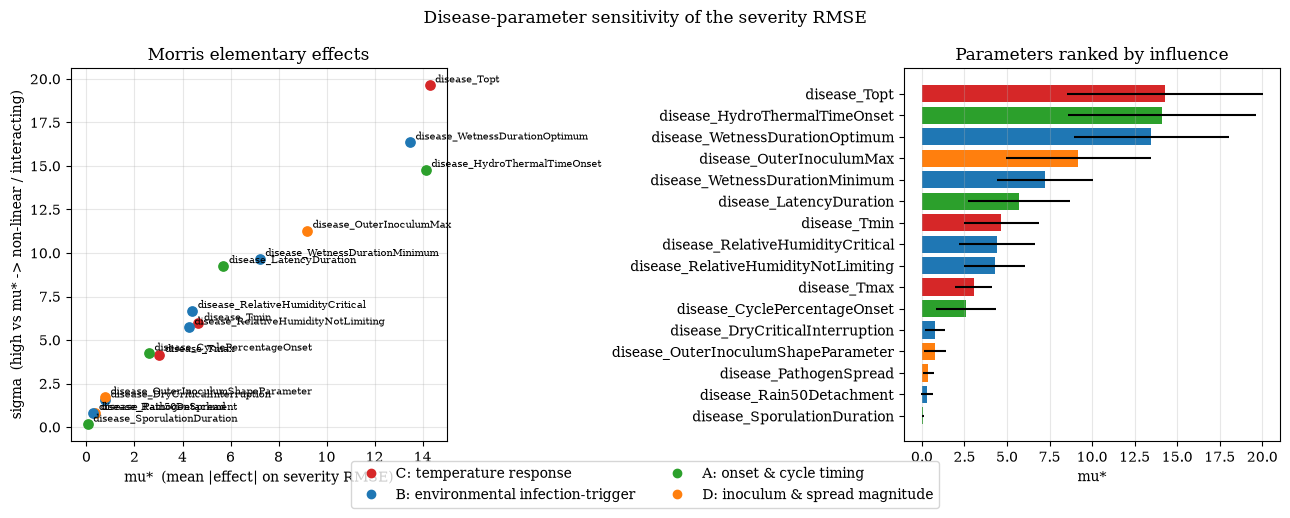

In [23]:
group_of = {p: g for g, names in GROUPS for p in names}
gname = lambda p: group_of.get(p.split('_', 1)[1], '')
gcolors = {
    "C: temperature response": "tab:red",
    "B: environmental infection-trigger": "tab:blue",
    "A: onset & cycle timing": "tab:green",
    "D: inoculum & spread magnitude": "tab:orange",
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for _, r in sa_df.iterrows():
    c = gcolors.get(gname(r["parameter"]), "0.5")
    axes[0].scatter(r["mu_star"], r["sigma"], color=c, s=45, zorder=3)
    axes[0].annotate(r["parameter"], (r["mu_star"], r["sigma"]), fontsize=7,
                     xytext=(4, 2), textcoords="offset points")
axes[0].set_xlabel("mu*  (mean |effect| on severity RMSE)")
axes[0].set_ylabel("sigma  (high vs mu* -> non-linear / interacting)")
axes[0].set_title("Morris elementary effects")
axes[0].grid(alpha=0.3)

order = sa_df.sort_values("mu_star")
bar_c = [gcolors.get(gname(p), "0.5") for p in order["parameter"]]
axes[1].barh(order["parameter"], order["mu_star"], color=bar_c,
             xerr=order["mu_star_conf"])
axes[1].set_xlabel("mu*")
axes[1].set_title("Parameters ranked by influence")
axes[1].grid(alpha=0.3, axis="x")

handles = [plt.Line2D([0], [0], marker="o", ls="", color=c, label=g)
           for g, c in gcolors.items()]
fig.legend(handles=handles, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Disease-parameter sensitivity of the severity RMSE", fontsize=12)
fig.tight_layout()
plt.show()

## 7. Calibrate five disease parameters

Calibrating every parameter the screen flags (eight to ten of them) does not
work here: different optimizer seeds reach the same RMSE with very different
values, several values end up on their bounds, and the fit does not carry
over to held-out seasons. The 109 severity observations cannot pin that many
parameters down. So only five are calibrated, and everything else keeps its
canonical FraNchEstYN septoria value from
`simpest/models/fr_disease_parameters.json`. No value is changed by hand.

**Calibrated** (site- and trial-specific, no published value for this trial):

| Parameter | Why it is calibrated |
|---|---|
| `OuterInoculumMax` | Primary inoculum pressure at the site. Shaner and Buechley (1995, Discussion) report that primary inoculum is abundant every year but do not quantify it. |
| `PathogenSpread` | Secondary infection rate. The paper attributes the year-to-year differences to splash dispersal carrying infection up the canopy (Discussion, p. 937). |
| `WetnessDurationOptimum` | Among the three most influential parameters in the screen above. |
| `Topt` | The most influential parameter in the screen and the one the severity data identify most consistently: calibrations with eight to ten free parameters put it between 19.7 and 22.4 °C in every seed. The canonical value of 18 °C is the lower edge of the canonical range (18–24 °C), and fixing it there raised the RMSE from 15.6 to 17.3. |
| `HydroThermalTimeOnset` | Among the three most influential parameters; sets when the epidemic starts, which the paper reports as varying strongly between years (Results, p. 930). |

**Fixed at the canonical value**: the cardinal temperatures `Tmin` and `Tmax`, `LatencyDuration`, the two relative-humidity thresholds,
`WetnessDurationMinimum` and the parameters the screen finds inert. The cell
below prints each fixed value. Two of them can be checked against the paper:
`Tmax` = 31 °C is consistent with Septoria tritici blotch developing poorly
at 29 °C (Wainshilbaum and Lipps 1991, cited on p. 936), and
`LatencyDuration` = 19.5 d is longer than the incubation period of about
12 d at 14–15 °C observed in 1990 (p. 937), as a latent period should be.

Optuna (TPE) runs from the same start once per seed and the best seed's
values are used. Each seed takes roughly 10 minutes with `n_jobs=5`.

In [24]:
# Calibrated set: see the table above for the reason behind each one.
CALIBRATED = ["OuterInoculumMax", "PathogenSpread", "WetnessDurationOptimum", "HydroThermalTimeOnset", "Topt"]

# sa_df names are runner keys ("disease_<Param>"); fr_cfg.disease_parameters is keyed by "<Param>".
bare = lambda p: p.split("_", 1)[1]
fixed = [bare(p) for p in sa_df["parameter"] if bare(p) not in CALIBRATED]
franchestyn.deactivate_calibration(fr_cfg.disease_parameters, set(fixed))
for p in CALIBRATED:
    fr_cfg.disease_parameters[p]["calibration"] = True
print("calibrated:", CALIBRATED)

# Fixed parameters keep the value FranchestynConfig loaded from
# simpest/models/fr_disease_parameters.json (canonical FraNchEstYN septoria
# set); nothing is overwritten here.
mu_star = sa_df.assign(parameter=sa_df["parameter"].map(bare)).set_index("parameter")["mu_star"]
fixed_table = pd.DataFrame({
    "value": {p: fr_cfg.disease_parameters[p]["value"] for p in fixed},
    "unit": {p: fr_cfg.disease_parameters[p].get("unit", "") for p in fixed},
    "mu_star": mu_star.loc[fixed].round(2),
    "source": "canonical FraNchEstYN (fr_disease_parameters.json)",
})
print("fixed:")
print(fixed_table.to_string())

# Same start for every seed; the best seed's values are written into fr_cfg.
# With fr_cfg.n_jobs > 1 Optuna evaluates trials in fixed batches, so each seed
# is reproducible.
CALIB_SEEDS = [1, 2, 3]
CALIB_TRIALS = 1200
calib = session.calibrate_seeds(CALIB_SEEDS, n_trials=CALIB_TRIALS)
best_run, start_params = calib.best, calib.start_params["disease"]
calib.table().round(3)

calibrated: ['OuterInoculumMax', 'PathogenSpread', 'WetnessDurationOptimum', 'HydroThermalTimeOnset', 'Topt']
fixed:
                             value              unit  mu_star                                              source
WetnessDurationMinimum        10.0             hours     7.22  canonical FraNchEstYN (fr_disease_parameters.json)
LatencyDuration               19.5              days     5.70  canonical FraNchEstYN (fr_disease_parameters.json)
Tmin                           7.5                °C     4.67  canonical FraNchEstYN (fr_disease_parameters.json)
RelativeHumidityCritical      60.0          unitless     4.41  canonical FraNchEstYN (fr_disease_parameters.json)
RelativeHumidityNotLimiting   90.0          unitless     4.27  canonical FraNchEstYN (fr_disease_parameters.json)
Tmax                          31.0                °C     3.04  canonical FraNchEstYN (fr_disease_parameters.json)
CyclePercentageOnset          25.0  hydrodegree days     2.60  canonical FraNchEstYN 

/home/rahaman/miniforge3/envs/simpest/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Trial 1/1200 CURR RMSE=18.9770 BEST RMSE=18.9770

Trial 2/1200 CURR RMSE=38.3050 BEST RMSE=18.9770

Trial 3/1200 CURR RMSE=35.9660 BEST RMSE=18.9770

...

Trial 1199/1200 CURR RMSE=18.1740 BEST RMSE=17.3200

Trial 1200/1200 CURR RMSE=18.0610 BEST RMSE=17.3200


Best RMSE: 17.3200
{'disease_OuterInoculumMax': 0.18619641546914184, 'disease_PathogenSpread': 0.2465856649761892, 'disease_WetnessDurationOptimum': 10.31471589310017, 'disease_Topt': 21.203352827220282, 'disease_HydroThermalTimeOnset': 0.6890678200958702}


seed 3: RMSE=17.320


,1,2,3
RMSE,17.013,17.794,17.320
OuterInoculumMax,0.140,0.309,0.186
PathogenSpread,0.299,0.298,0.247
WetnessDurationOptimum,12.753,42.418,10.315
Topt,20.012,18.432,21.203
HydroThermalTimeOnset,13.376,5.317,0.689


## 8. Simulated severity and yield loss

A forward run with the calibrated disease parameters gives, per season, the
septoria severity and the disease-limited (actual) yield next to the
attainable yield from the calibrated torchcrop run.


In [25]:
# Forward run with the best seed's parameters.
result = session.run_forward()
summary = result["outputs"]["summary"]

# FraNchEstYN stores disease severity as a 0-1 fraction internally;
# build_season_summary expects that and multiplies by 100 for AUDPC, so
# convert to percent only after the summary is built.
simulation_df = fr_diagnostics.simulation_frame(result, severity_percent=False)
season_summary = franchestyn.build_season_summary(simulation_df, site=fr_cfg.site, variety=fr_cfg.variety)
simulation_df["DiseaseSeverity"] = simulation_df["DiseaseSeverity"] * 100.0
season_summary["DiseaseSeverity"] = season_summary["DiseaseSeverity"] * 100.0

print(f"FraNchEstYN completed (best seed: {best_run['seed']})")
print("RMSE (disease severity vs reference):", summary.get("rmse"))
print(f"{len(season_summary)} growing seasons summarised")
season_summary

FraNchEstYN completed (best seed: 1)
RMSE (disease severity vs reference): 17.013
19 growing seasons summarised


,GrowingSeason,Site,Variety,AUDPC,DiseaseSeverity,YieldAttainable,YieldActual,YieldLossRaw,YieldLossPerc,AGBattainable,AGBactual,AveTx,AveTn,AveRHx,AveRHn,TotalPrec,TotalRad,TotalLW
0,1972,west_lafayette_indiana,Generic,2663.060226,74.986795,3281.3910,609.258677,2672.132323,81.432914,10373.9400,7087.791656,11.215299,2.895522,87.839552,57.205224,811.0,3291.878,1611.0
1,1973,west_lafayette_indiana,Generic,2412.320481,56.085947,2175.2385,744.090572,1431.147928,65.792690,8367.9720,6204.170676,12.291697,3.093863,87.519856,57.162455,952.8,3522.663,1593.0
2,1974,west_lafayette_indiana,Generic,1981.324443,58.994978,3049.7250,1211.076787,1838.648213,60.288984,10691.5320,7949.866654,11.795636,3.059636,87.974545,54.836364,680.0,3701.865,1492.0
3,1975,west_lafayette_indiana,Generic,1987.439792,50.147759,2057.4192,872.007811,1185.411389,57.616425,8737.8070,6854.700778,13.139259,2.817407,85.296296,51.000000,617.8,3829.207,1134.0
4,1976,west_lafayette_indiana,Generic,1774.461939,62.623839,3456.1780,1952.886581,1503.291419,43.495775,10872.2810,9263.989790,10.096565,0.433588,81.419847,48.893130,553.7,3684.978,816.0
5,1977,west_lafayette_indiana,Generic,2170.456625,68.065517,3075.2395,1131.066892,1944.172608,63.220201,10515.2000,7939.163180,9.456296,0.335556,87.362963,59.362963,670.0,3731.382,1414.0
6,1978,west_lafayette_indiana,Generic,2407.331589,60.669059,2370.3990,540.848325,1829.550675,77.183237,9965.3540,7203.548091,10.634783,1.272101,86.710145,56.083333,743.5,3699.899,1467.0
7,1979,west_lafayette_indiana,Generic,2523.028643,80.015720,3616.4004,1069.946176,2546.454224,70.414057,11455.8880,8627.792317,11.262271,2.158242,85.739927,53.937729,761.9,3577.604,1379.0
8,1980,west_lafayette_indiana,Generic,2440.332673,70.623049,2518.1323,631.642320,1886.489980,74.916238,10040.8960,7601.694180,11.487546,2.183516,84.238095,51.435897,802.1,3667.066,1076.0
9,1981,west_lafayette_indiana,Generic,1795.038671,56.801259,3251.7358,1705.740649,1545.995151,47.543689,10768.8280,8885.428909,10.649104,0.988889,87.318996,56.172043,836.7,3827.249,1376.0


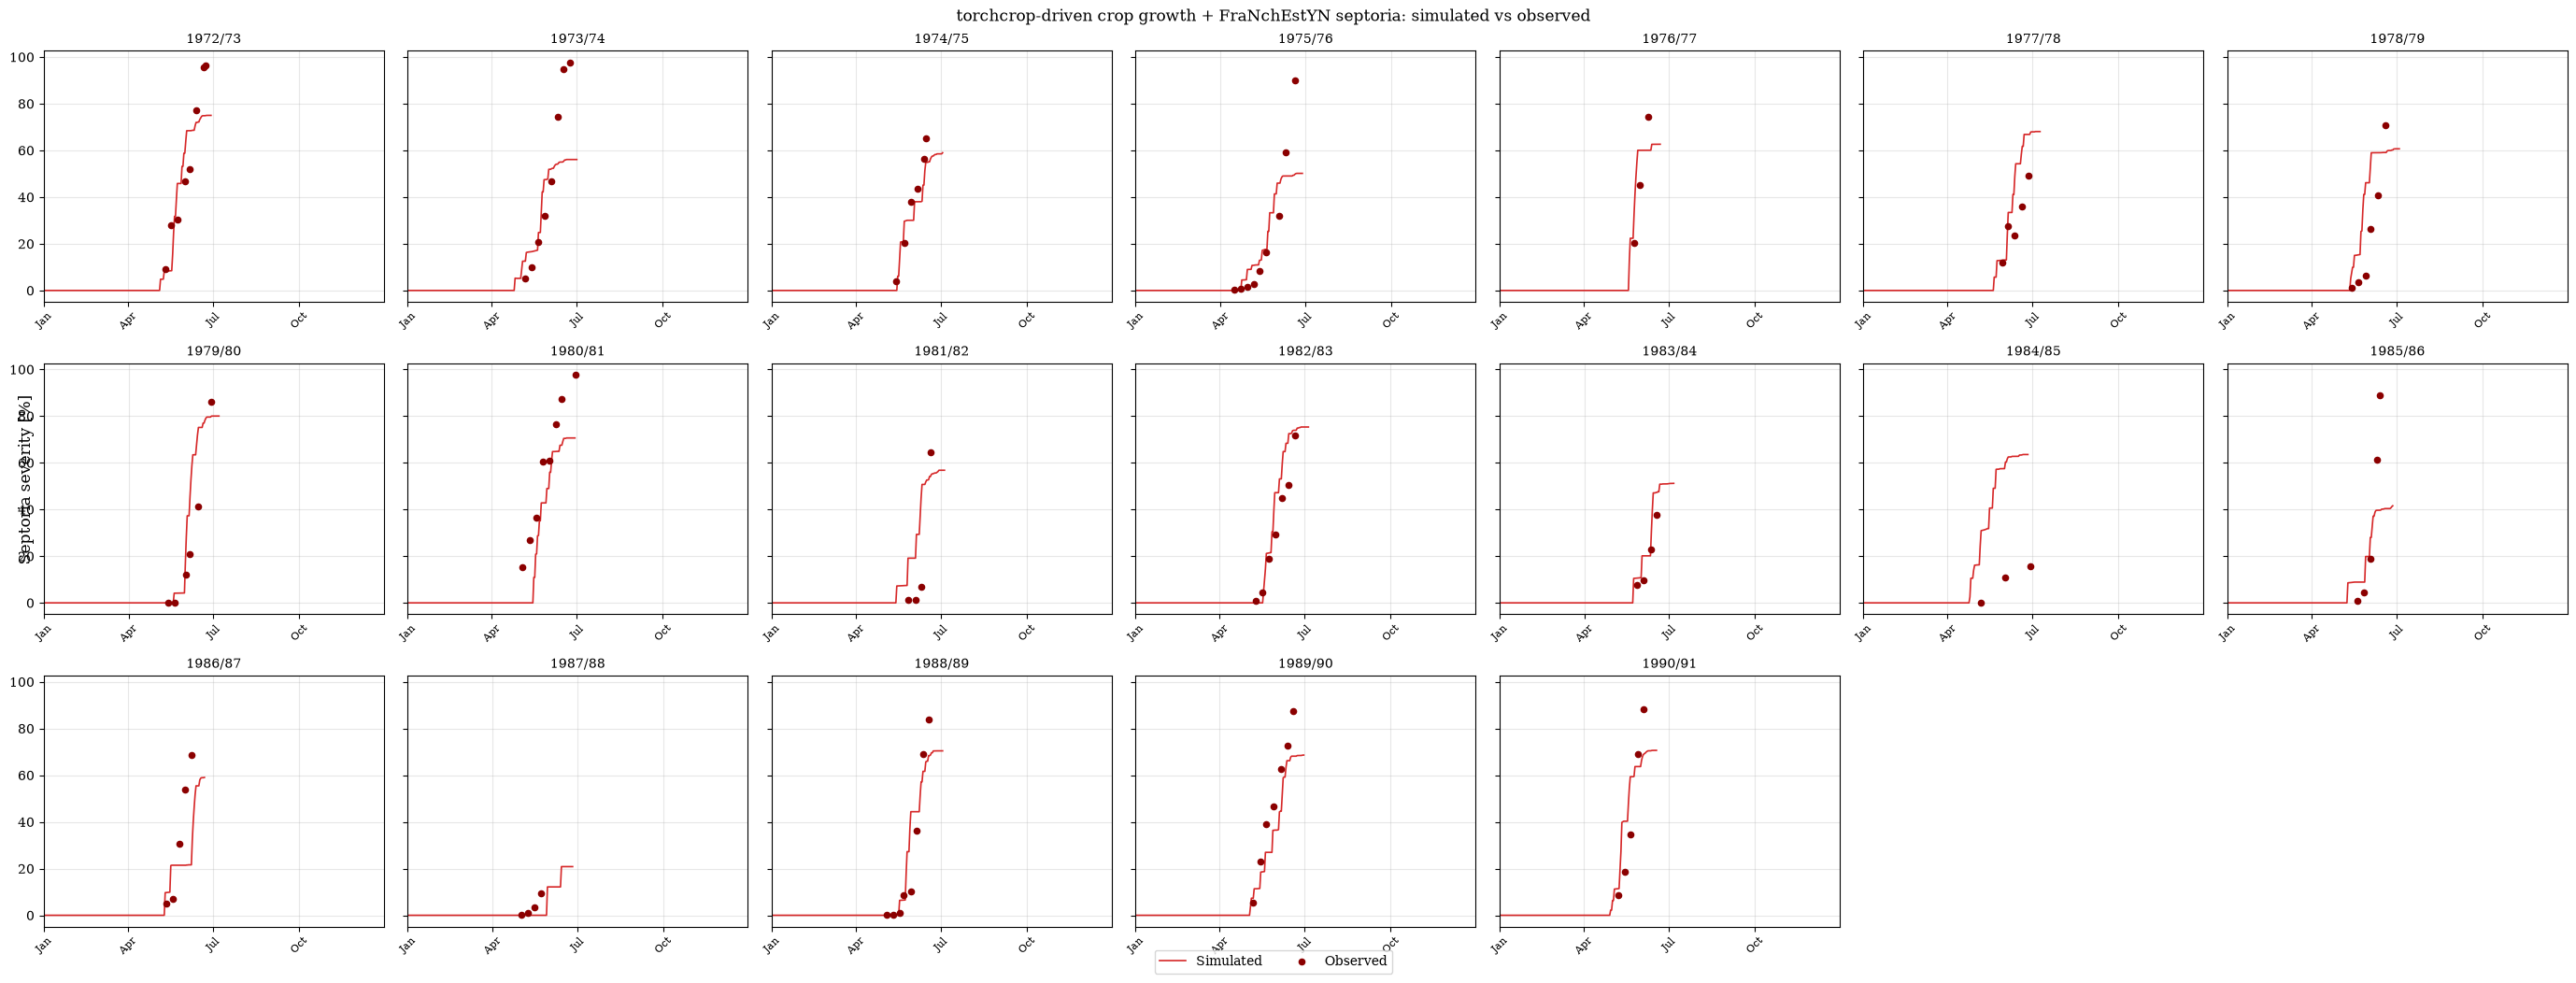

In [26]:
n_seasons = len(dataset.locations)
n_cols = 7
n_rows = int(np.ceil(n_seasons / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(28, 3.5 * n_rows), sharey=True)
axes_flat = axes.ravel()
ref_dis = ref_df[ref_df[FRANCH_DISEASE].notna()]

for i, sow_year in enumerate(dataset.locations):
    ax = axes_flat[i]
    harvest_yr = sow_year + 1
    sub = simulation_df[simulation_df["GrowingSeason"] == sow_year]
    ax.plot(sub["Date"], sub["DiseaseSeverity"], color="tab:red", lw=1.2, label="Simulated")

    ref_yr = ref_dis[ref_dis["year"] == harvest_yr]
    if not ref_yr.empty:
        ref_dates = pd.Timestamp(year=harvest_yr, month=1, day=1) + pd.to_timedelta(ref_yr["DOY"] - 1, unit="D")
        ax.scatter(ref_dates, ref_yr[FRANCH_DISEASE], color="darkred", s=20, zorder=5, label="Observed")

    ax.set_title(f"{sow_year}/{str(harvest_yr)[2:]}", fontsize=10)
    ax.set_xlim(pd.Timestamp(f"{harvest_yr}-01-01"), pd.Timestamp(f"{harvest_yr}-12-31"))
    ax.xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
    ax.tick_params(axis="x", labelsize=8, rotation=45)
    ax.grid(alpha=0.3)

# Hide any unused panels (n_seasons may not fill the grid exactly).
for ax in axes_flat[n_seasons:]:
    ax.axis("off")

handles, labels = axes_flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.01))
fig.supylabel("Septoria severity [%]")
fig.suptitle("torchcrop-driven crop growth + FraNchEstYN septoria: simulated vs observed", fontsize=12)
fig.tight_layout()
plt.show()

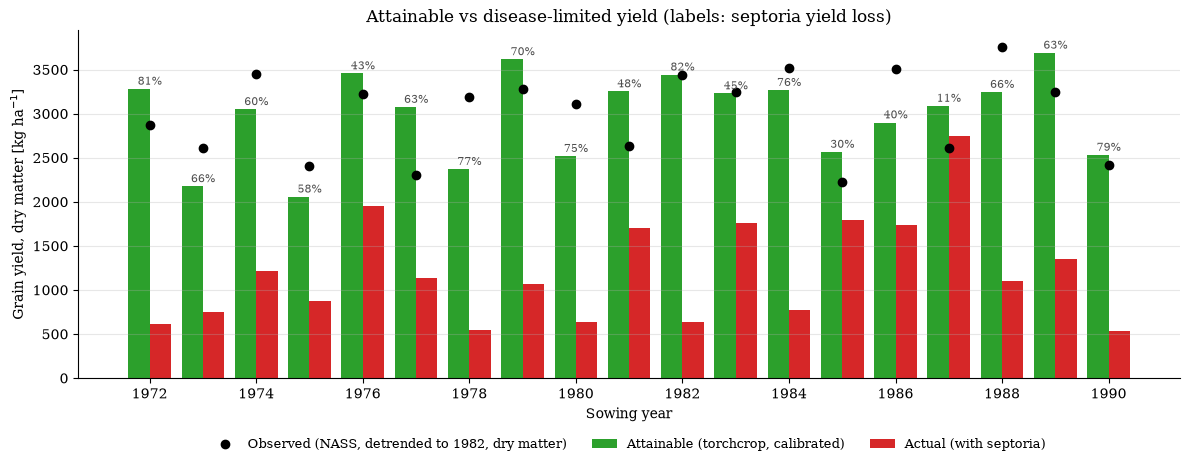

,GrowingSeason,DiseaseSeverity,AUDPC,YieldAttainable,YieldActual,YieldLossPerc
0,1972,75.0,2663.1,3281.4,609.3,81.4
1,1973,56.1,2412.3,2175.2,744.1,65.8
2,1974,59.0,1981.3,3049.7,1211.1,60.3
3,1975,50.1,1987.4,2057.4,872.0,57.6
4,1976,62.6,1774.5,3456.2,1952.9,43.5
5,1977,68.1,2170.5,3075.2,1131.1,63.2
6,1978,60.7,2407.3,2370.4,540.8,77.2
7,1979,80.0,2523.0,3616.4,1069.9,70.4
8,1980,70.6,2440.3,2518.1,631.6,74.9
9,1981,56.8,1795.0,3251.7,1705.7,47.5


In [27]:
# Attainable (calibrated torchcrop) vs disease-limited yield per season, with the
# detrended NASS yield (dry matter) for reference.
x = season_summary["GrowingSeason"].to_numpy()
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.bar(x - 0.2, season_summary["YieldAttainable"], width=0.4, color="#2ca02c", label="Attainable (torchcrop, calibrated)")
ax.bar(x + 0.2, season_summary["YieldActual"], width=0.4, color="tab:red", label="Actual (with septoria)")
ax.plot(cmp_df["sow_year"], cmp_df["observed_detrended"], color="black", lw=0, marker="o", ms=6,
        label=f"Observed (NASS, detrended to {ref_harvest_year}, dry matter)")
for xi, att, loss in zip(x, season_summary["YieldAttainable"], season_summary["YieldLossPerc"]):
    ax.annotate(f"{loss:.0f}%", (xi, att), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, color="0.3")

ax.set_xlabel("Sowing year")
ax.set_ylabel("Grain yield, dry matter [kg ha$^{-1}$]")
ax.set_title("Attainable vs disease-limited yield (labels: septoria yield loss)")
ax.set_xticks(x[::2])
ax.set_ylim(0, None)
ax.grid(alpha=0.3, axis="y")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False, fontsize=9)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

season_summary[["GrowingSeason", "DiseaseSeverity", "AUDPC", "YieldAttainable", "YieldActual", "YieldLossPerc"]].round(1)

## 9. Error diagnostics: simulated vs observed

At every reference observation date (severity from `thisDisease`, canopy
closure from `FINT`), match the simulated value on that same calendar date
and take the residual `simulated - observed`. A parity plot shows overall
bias/spread against the 1:1 line; the residual-over-time plot shows whether
errors cluster in a particular part of the season (color marks over- vs
under-prediction).


In [28]:
severity_err = fr_diagnostics.match_ref_to_sim(simulation_df, ref_df, seasons, FRANCH_DISEASE, "DiseaseSeverity")
fint_err = fr_diagnostics.match_ref_to_sim(simulation_df, ref_df, seasons, "FINT", "LightInterception")

sev_stats, fint_stats = fr_diagnostics.error_stats(severity_err), fr_diagnostics.error_stats(fint_err)
print(f"severity: n={sev_stats['n']}  RMSE={sev_stats['RMSE']:.2f}  MAE={sev_stats['MAE']:.2f}")
print(f"fint:     n={fint_stats['n']}  RMSE={fint_stats['RMSE']:.3f}  MAE={fint_stats['MAE']:.3f}")

severity: n=109  RMSE=18.05  MAE=13.83
fint:     n=20  RMSE=0.175  MAE=0.167


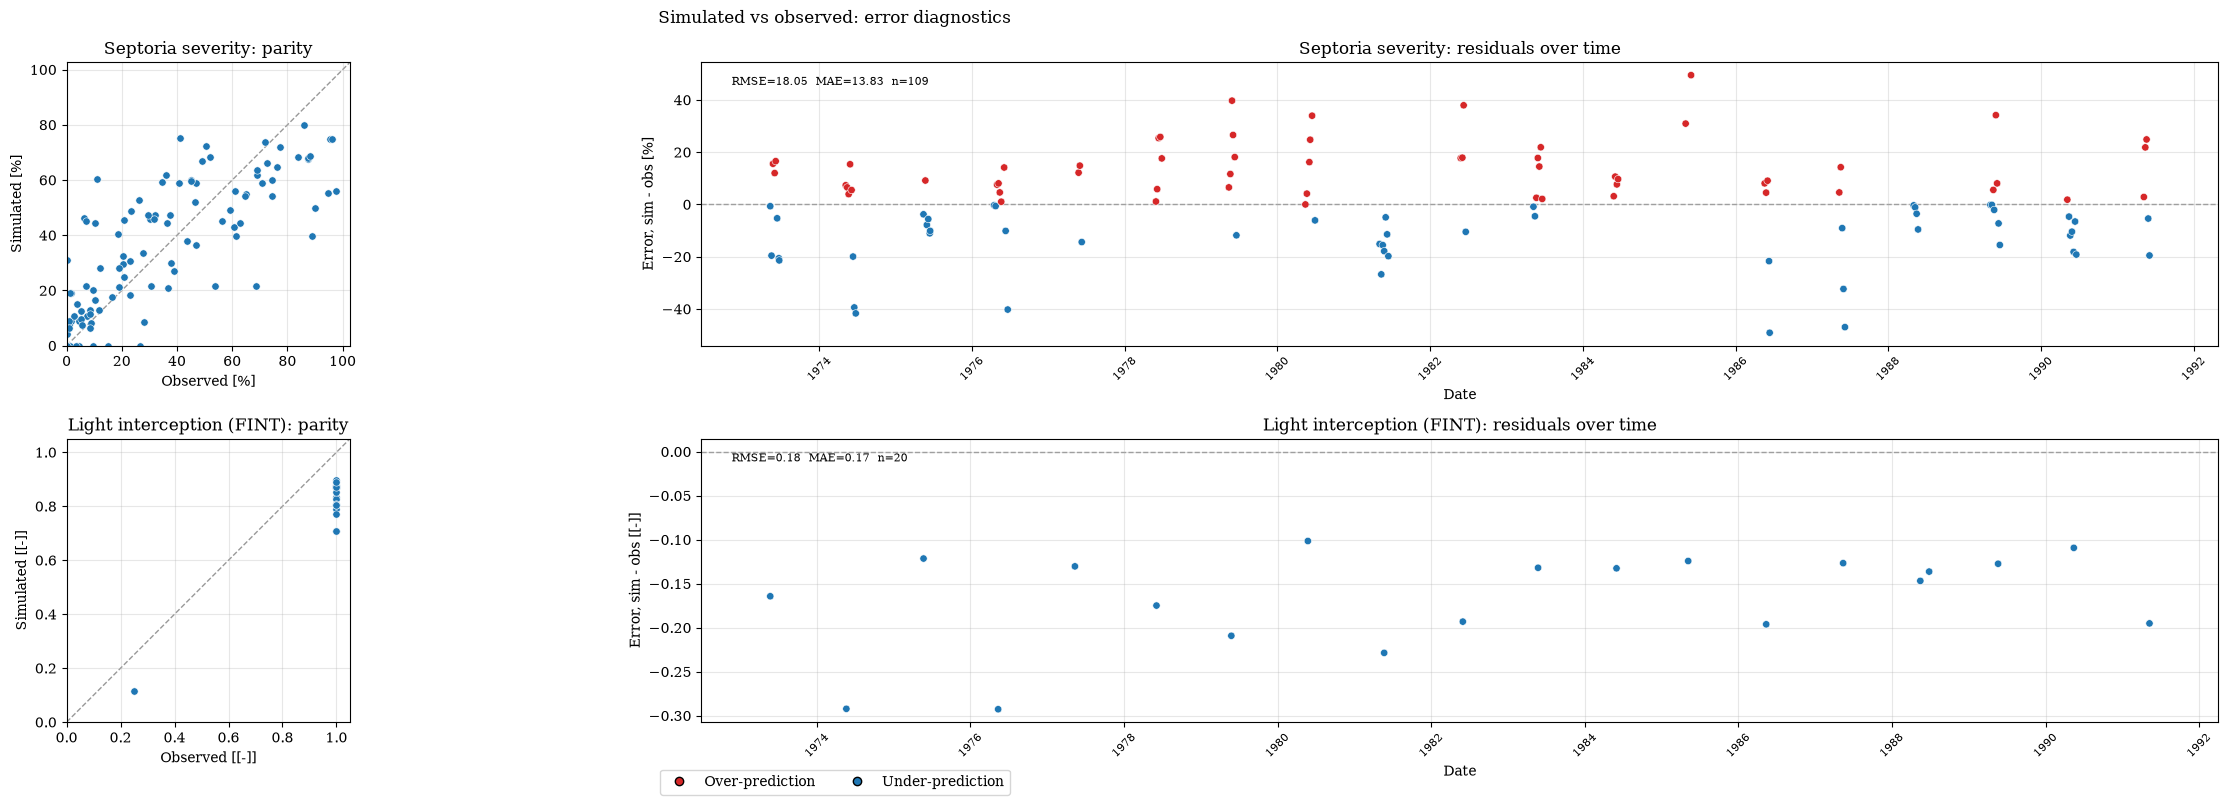

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(28, 8))

panels = [(severity_err, "Septoria severity", "%"), (fint_err, "Light interception (FINT)", "[-]")]
for row, (err_df, label, unit) in enumerate(panels):
    ax_parity, ax_resid = axes[row]

    lo, hi = 0, max(err_df["observed"].max(), err_df["simulated"].max()) * 1.05
    ax_parity.plot([lo, hi], [lo, hi], color="0.6", lw=1, ls="--", zorder=1)
    ax_parity.scatter(err_df["observed"], err_df["simulated"], s=28, color="tab:blue", edgecolor="white", linewidth=0.4, zorder=2)
    ax_parity.set_xlim(lo, hi)
    ax_parity.set_ylim(lo, hi)
    ax_parity.set_aspect("equal")
    ax_parity.set_xlabel(f"Observed [{unit}]")
    ax_parity.set_ylabel(f"Simulated [{unit}]")
    ax_parity.set_title(f"{label}: parity")
    ax_parity.grid(alpha=0.3)

    err_colors = np.where(err_df["error"] >= 0, "tab:red", "tab:blue")
    ax_resid.axhline(0, color="0.6", lw=1, ls="--", zorder=1)
    ax_resid.scatter(err_df["date"], err_df["error"], s=28, color=err_colors, edgecolor="white", linewidth=0.4, zorder=2)
    ax_resid.set_xlabel("Date")
    ax_resid.set_ylabel(f"Error, sim - obs [{unit}]")
    ax_resid.set_title(f"{label}: residuals over time")
    ax_resid.tick_params(axis="x", rotation=45, labelsize=8)
    ax_resid.grid(alpha=0.3)

    rmse = np.sqrt((err_df["error"] ** 2).mean())
    mae = err_df["error"].abs().mean()
    ax_resid.text(0.02, 0.95, f"RMSE={rmse:.2f}  MAE={mae:.2f}  n={len(err_df)}",
                  transform=ax_resid.transAxes, fontsize=8, va="top")

legend_handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor="tab:red", markersize=6, label="Over-prediction"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="tab:blue", markersize=6, label="Under-prediction"),
]
fig.legend(handles=legend_handles, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Simulated vs observed: error diagnostics", fontsize=12)
fig.tight_layout()
plt.show()

### Per-season diagnostics

One row per season: fit quality (same-date RMSE and bias), simulated and
observed peak severity, when the simulated season ends compared with the last
observation, and April–June wet hours. The calibration objective only scores
observations that fall inside a simulated season, so `n_obs_after_season`
counts observations the optimizer never sees. Fully-wet days (24 wet hours)
are mostly an artifact of daily weather, where rain is spread evenly over the
day.


In [30]:
season_diag = fr_diagnostics.season_diagnostics(simulation_df, ref_df, severity_err, seasons, FRANCH_DISEASE)
season_diag.round(1)

,rmse,bias,peak_sim,peak_obs,sim_end,last_obs,n_obs,n_obs_after_season,wet_hours_AMJ,fully_wet_days_AMJ
season,,,,,,,,,,
1972/73,15.6,-2.9,75.0,96.3,1973-06-29,1973-06-23,8,0,490.0,0
1973/74,22.5,-7.8,56.1,97.8,1974-07-01,1974-06-24,8,0,550.0,1
1974/75,8.3,-4.9,59.0,65.0,1975-07-03,1975-06-15,6,0,413.0,0
1975/76,15.1,-1.8,50.1,90.0,1976-06-28,1976-06-20,9,0,321.0,0
1976/77,13.8,4.2,62.6,74.4,1977-06-22,1977-06-09,3,0,286.0,2
1977/78,18.2,15.2,68.1,49.2,1978-07-09,1978-06-27,5,0,442.0,0
1978/79,22.1,15.1,60.7,70.9,1979-07-04,1979-06-19,6,0,451.0,0
1979/80,18.6,12.2,80.0,86.1,1980-07-07,1980-06-29,6,0,515.0,1
1980/81,17.1,-15.9,70.6,97.8,1981-06-29,1981-06-30,8,1,522.0,2


### Season AUDPC: simulated vs observed

Point-wise RMSE is sensitive to a few days of timing error. The area under the
disease progress curve (AUDPC) summarises each season's epidemic intensity in
one number, and it is closer to what drives yield loss. Observed and
simulated AUDPC are both integrated over each season's matched observation
dates with the trapezoid rule (`fr_diagnostics.season_audpc`), in % × days.
Observations after simulated maturity are not matched, so those seasons'
windows are shorter than the field assessments.

Because both AUDPCs grow with the length of the window, and the windows range
from about two to eight weeks, part of their correlation comes from window
length alone. The mean severity over the window (AUDPC divided by its days)
removes that and is the fairer test of season-to-season intensity.

Shaner and Buechley (1995, Tables 5 and 6) report AUDPC for every season from
the first to the last assessment. Their values, transcribed in
`disease/disease.csv` (`AUDPC_Y_recommended`, × 100),
are shown as a cross-check of the reference severities: the two agree
closely in most seasons. The CSV notes where the paper's tables are
inconsistent; 1975 and 1976 have no reliable paper value.


AUDPC, n = 19: Pearson r = 0.79, rank r = 0.82
mean severity over the window: Pearson r = 0.55, rank r = 0.43
observed 67-2227, simulated 0-2205 % x days


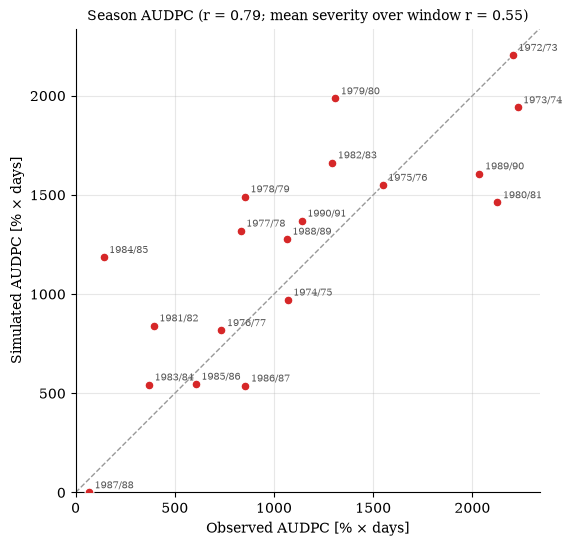

,n,first,last,observed,simulated,paper,days
season,,,,,,,
1972,8,1973-05-11,1973-06-23,2204.0,2205.0,2259.0,43
1973,8,1974-05-07,1974-06-24,2227.0,1941.0,2256.0,48
1974,6,1975-05-14,1975-06-15,1069.0,971.0,NaN,32
1975,9,1976-04-16,1976-06-20,1548.0,1550.0,NaN,65
1976,3,1977-05-25,1977-06-09,735.0,818.0,698.0,15
1977,5,1978-05-30,1978-06-27,832.0,1319.0,787.0,28
1978,6,1979-05-14,1979-06-19,853.0,1492.0,819.0,36
1979,6,1980-05-14,1980-06-29,1308.0,1986.0,1329.0,46
1980,7,1981-05-04,1981-06-15,2126.0,1462.0,2954.0,42


In [31]:
audpc = fr_diagnostics.season_audpc(severity_err)

# Paper AUDPC, proportion x days -> % x days, keyed by harvest (crop) year.
paper = pd.read_csv(DATA_DIR / "disease" / "disease.csv").set_index("crop_year")
audpc["paper"] = (paper["AUDPC_Y_recommended"] * 100).reindex(audpc.index + 1).to_numpy()

# Mean severity over the window removes the effect of window length on AUDPC.
audpc["days"] = (audpc["last"] - audpc["first"]).dt.days
mean_obs, mean_sim = audpc["observed"] / audpc["days"], audpc["simulated"] / audpc["days"]

r = np.corrcoef(audpc["observed"], audpc["simulated"])[0, 1]
r_rank = audpc["observed"].rank().corr(audpc["simulated"].rank())
r_mean = np.corrcoef(mean_obs, mean_sim)[0, 1]
print(f"AUDPC, n = {len(audpc)}: Pearson r = {r:.2f}, rank r = {r_rank:.2f}")
print(f"mean severity over the window: Pearson r = {r_mean:.2f}, "
      f"rank r = {mean_obs.rank().corr(mean_sim.rank()):.2f}")
print(f"observed {audpc['observed'].min():.0f}-{audpc['observed'].max():.0f}, "
      f"simulated {audpc['simulated'].min():.0f}-{audpc['simulated'].max():.0f} % x days")

fig, ax = plt.subplots(figsize=(5.8, 5.8))
lim = 1.05 * audpc[["observed", "simulated"]].to_numpy().max()
ax.plot([0, lim], [0, lim], color="0.6", lw=1, ls="--", zorder=1)
ax.scatter(audpc["observed"], audpc["simulated"], s=40, color="tab:red", edgecolor="white", linewidth=0.8, zorder=3)
for season, row in audpc.iterrows():
    ax.annotate(f"{season}/{str(season + 1)[2:]}", (row["observed"], row["simulated"]), xytext=(4, 3),
                textcoords="offset points", fontsize=7, color="0.35")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_aspect("equal")
ax.set_xlabel("Observed AUDPC [% × days]")
ax.set_ylabel("Simulated AUDPC [% × days]")
ax.set_title(f"Season AUDPC (r = {r:.2f}; mean severity over window r = {r_mean:.2f})", fontsize=10)
ax.grid(alpha=0.3)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

audpc.round({"observed": 0, "simulated": 0, "paper": 0})

## 10. Hold-out check

Every result above is calibrated and scored on the same 19 seasons. To see
whether the poorly fitted seasons are a compromise of that joint fit or a
structural limit of the model, recalibrate on 13 seasons only (same starting
values, bounds, trial budget and seed as the best all-seasons run) and score
the 6 held-out seasons. The held-out set mixes well- and poorly-fitted
seasons. If the train-only fit scores much worse on the held-out seasons than
the all-seasons fit does, the calibrated parameters do not generalise to
seasons they were not fitted on.


In [32]:
HOLDOUT = [1973, 1975, 1978, 1981, 1984, 1988]  # sowing years
ref_train = ref_df[~ref_df["year"].isin([y + 1 for y in HOLDOUT])]

# Same starting values, bounds, trial budget and seed as the best all-seasons run.
ho_cfg = copy.deepcopy(fr_cfg)
ho_cfg.disease_parameters = copy.deepcopy(start_params)
ho_cfg.is_calibration, ho_cfg.n_trials, ho_cfg.seed = True, CALIB_TRIALS, best_run["seed"]

train_session = FranchestynSession(
    ho_cfg, FRANCH_START_YEAR, FRANCH_END_YEAR, weather_df=weather_df,
    management_df=management_df, crop_model_df=crop_model_df, ref_df=ref_train,
)
ho_best = train_session.run()
franchestyn.apply_best_params(ho_cfg, ho_best["outputs"]["summary"]["best_params"])

# Score every season with the train-only parameters, on the all-seasons runner.
ho_cfg.is_calibration = False
ho_sim = fr_diagnostics.simulation_frame(
    franchestyn.run_franchestyn(config=ho_cfg, runner=session.runner, **session.inputs))

holdout_table = pd.DataFrame({
    "all_seasons_fit": fr_diagnostics.season_rmse(severity_err),
    "train_only_fit": fr_diagnostics.season_rmse(
        fr_diagnostics.match_ref_to_sim(ho_sim, ref_df, seasons, FRANCH_DISEASE, "DiseaseSeverity")),
})
holdout_table["held_out"] = holdout_table.index.isin(HOLDOUT)
print(holdout_table.groupby("held_out").mean().round(2))
holdout_table.round(1)

- Calibrating 5 using Optuna (TPE), n_trials=1200.
- Parameters:
['disease_OuterInoculumMax', 'disease_PathogenSpread', 'disease_WetnessDurationOptimum', 'disease_Topt', 'disease_HydroThermalTimeOnset']
- Evaluating trials in batches of 5 across 5 worker processes.


Trial 1/1200 CURR RMSE=17.0190 BEST RMSE=17.0190

Trial 2/1200 CURR RMSE=39.6140 BEST RMSE=17.0190

Trial 3/1200 CURR RMSE=37.8170 BEST RMSE=17.0190

Trial 4/1200 CURR RMSE=17.7700 BEST RMSE=17.0190

...

Trial 1199/1200 CURR RMSE=17.3430 BEST RMSE=15.6450

Trial 1200/1200 CURR RMSE=17.7470 BEST RMSE=15.6450


Best RMSE: 15.6450
{'disease_OuterInoculumMax': 0.1622082629186297, 'disease_PathogenSpread': 0.2885853065734072, 'disease_WetnessDurationOptimum': 14.311062396446442, 'disease_Topt': 20.005468553167486, 'disease_HydroThermalTimeOnset': 12.02174981682989}


          all_seasons_fit  train_only_fit
held_out                                 
False               15.24           15.66
True                23.06           23.98


,all_seasons_fit,train_only_fit,held_out
season,,,
1972,15.6,15.9,False
1973,22.5,21.4,True
1974,8.3,7.2,False
1975,15.1,14.9,True
1976,13.8,15.4,False
1977,18.2,21.0,False
1978,22.1,24.4,True
1979,18.6,20.5,False
1980,17.1,15.4,False
